In [2]:
import numpy as np
import seaborn as sns
from networks.linear_network import LinearNetwork
from utils import get_random_regression_task, get_lambda_balanced, get_ntk, kernel_distance,BlindColours
from qqt.lambda_balanced_extra_dim_clean import QQT_lambda_balanced_unequal
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from qqt.lambda_balanced_extra_dim_clean import MTL_QQT_lambda_balanced_bottleneck
from qqt.lambda_balanced_extra_dim_bottel import QQT_lambda_balanced_unequal
from utils import get_random_regression_task, get_lambda_balanced,get_lambda_balanced_botteld, get_ntk, reshape_matrix, kernel_distance, cosine_similarity,BlindColours, zero_balanced_weights
import matplotlib as mpl
import matplotlib.patheffects as pe
import matplotlib.gridspec as gridspec
from string import ascii_lowercase as _abc
import torch
import torch.nn.functional as F
from matplotlib import ticker
from matplotlib.ticker import FormatStrFormatter

from utils import whiten
from networks.linear_network import *
from utils import MTL_get_lambda_balanced_STLex
from qqt.lambda_balanced_extra_dim_clean import MTL_QQT_lambda_balanced_unequal

(array([[ 0.42685306,  0.75011194, -1.23035372],
       [ 0.3488357 , -0.8056247 , -0.79109201],
       [-1.27548335,  0.1758864 , -0.43256515]]), array([[ 0.20791833, -0.18217838,  0.88599424],
       [-1.09230322, -0.50839516,  0.05878577],
       [-0.00164373, -0.287414  ,  0.18488425]]), array([[1.92355841, 0.        , 0.        ],
       [0.        , 1.33340381, 0.        ],
       [0.        , 0.        , 0.19852155]]), array([[ 1.02228266e+00, -1.11022302e-15,  4.71844785e-16],
       [-1.11022302e-15,  1.02228266e+00,  1.30451205e-15],
       [ 4.71844785e-16,  1.30451205e-15,  1.02228266e+00]]))
Sisdezegoed [1.34939366e-08 5.52429585e-09]
Shi [[1.00000001e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 4.29119086e-05 0.00000000e+00 0.00000000e+00]]
S_1 [[0.00011616 0.        ]
 [0.         0.        ]]
U [[-0.99742359  0.07173686]
 [ 0.07173686  0.99742359]]
sxi
w1 [[ 6.61089212e-05  9.51530597e-05]
 [-4.75469636e-06 -6.84361351e-06]]
w2 [[-0.10204149  0.070

In [3]:
from networks.linear_network import *
from utils import MTL_get_lambda_balanced_STLex
from qqt.lambda_balanced_extra_dim_clean import MTL_QQT_lambda_balanced_unequal
import random


seed=5434
random.seed(seed)
np.random.seed(seed)
np.random.default_rng(seed=seed)

learning_rate = 0.00002
training_steps = 20000
in_dim=4
out_dim_1=1
out_dim_2=1
hidden_dim=2
batch_size=100



def get_random_regression_task_MTL(batch_size, in_dim, out_dim_1, out_dim_2):
    X = np.random.randn(batch_size, in_dim)
    Y1 = np.random.randn(batch_size, out_dim_1)
    Y2= np.random.randn(batch_size, out_dim_2)
    X_whitened = whiten(X)
    return X_whitened, Y1, Y2


def get_MTL_Tasks(batch_size, in_dim, out_dim_1, out_dim_2, alpha_scales=(1,1), alignment_factor=0.3, whitenli=True, seed=31):
    rng = np.random.default_rng(seed)

    X = np.random.randn(batch_size, in_dim)

    Q_full, _ = np.linalg.qr(rng.standard_normal((in_dim, in_dim)))
    W1=Q_full[:, :out_dim_1].T
    W2 = alignment_factor*W1 + (1-alignment_factor)*Q_full[:, out_dim_1:2*out_dim_1].T
    W2 = W2 / np.linalg.norm(W2, 'fro') * np.linalg.norm(W1, 'fro')
    W1= W1/ np.linalg.norm(W1, 'fro')*np.linalg.norm(W2,'fro')
    if whitenli == True:
        X = whiten(X)
    Y1 = alpha_scales[0]*W1 @ X.T
    Y2 = alpha_scales[1]*W2 @ X.T

    if out_dim_1 == 1:
      Y1=Y1.reshape(1, batch_size)
      Y2=Y2.reshape(1, batch_size)

    return X, Y1, Y2


def get_MTL_Tasks_spectrum(batch_size, in_dim, alphas, alpha_scales=(1,1),
                           whitenli=True, seed=None):
    """Two linear tasks whose overlap matrix O_12 has singular values exactly `alphas`.
       alphas[k] in [0,1]: 1 = shared mode, 0 = orthogonal, in-between = conflicting.
       Requires 2*len(alphas) <= in_dim  (i.e. N_o1 + N_o2 < N_1)."""
    rng = np.random.default_rng(seed)
    alphas = np.asarray(alphas, float)
    d = len(alphas)
    assert 2*d <= in_dim, f"need 2*{d} <= {in_dim} (N_o1+N_o2 < N_1)"
    assert np.all((alphas >= 0) & (alphas <= 1)), "alphas must be in [0,1]"

    X = np.random.randn(batch_size, in_dim)
    Q, _ = np.linalg.qr(rng.standard_normal((in_dim, in_dim)))
    A, B = Q[:, :d], Q[:, d:2*d]                       # mutually orthonormal blocks
    W1 = A.T
    W2 = alphas[:, None]*A.T + np.sqrt(1-alphas**2)[:, None]*B.T

    if whitenli:
        X = whiten(X)
    Y1 = alpha_scales[0]*W1 @ X.T
    Y2 = alpha_scales[1]*W2 @ X.T
    return X, Y1, Y2

In [ ]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from datasets import get_MTL_Tasks
from networks.linear_network import MTL_linearnetwork
from utils import MTL_get_lambda_balanced_STLex


# ----------------------------- experiment configuration
SEEDS = [0]

IN_DIM = 5
HIDDEN_DIM = 2
OUT_DIM_1 = 1
OUT_DIM_2 = 1
BATCH_SIZE = 10

LEARNING_RATE = 2e-4
TRAINING_STEPS = 20000      # use 200_000 for the full run
WARMUP_STEPS = 20
EMA_BETA = 0.9
EPS = 1e-8

# Heatmap sweep
ALIGNMENT_FACTORS = np.linspace(0.0, 1.0, 5)
LOG_RATIOS = np.linspace(0.0, 3.0, 5)
ALPHA_2 = 2.0

# Static weight sweep:
# r = alpha-like ratio controlling w1 / w2
STATIC_CANDIDATES = 2.0 ** np.linspace(-2.0, 2.0, 9)


# ----------------------------- one numerical run

def run_case(
    alignment_factor,
    alpha_1,
    alpha_2,
    weighting_mode="none",
    static_ratio=1.0,
    seed=0,
    beta=None,
):
    random.seed(seed)
    np.random.seed(seed)
    if beta is None:
        beta = EMA_BETA
    X, Y1, Y2 = get_MTL_Tasks(
        BATCH_SIZE,
        IN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        alpha_scales=(alpha_1, alpha_2),
        alignment_factor=alignment_factor,
        seed=seed,  # important
    )

    init_ws, init_w1, init_w2 = MTL_get_lambda_balanced_STLex(
        0,
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        sigma_weights=0.01,
    )

    model = MTL_linearnetwork(
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        init_ws=init_ws.copy(),
        init_w1=init_w1.copy(),
        init_w2=init_w2.copy(),
    )

    (
        wslist,
        w1list,
        w2list,
        losses1,
        losses2,
        cossim,
        gradmag1,
        gradmag2,
    ) = model.trainMTL(
        X.T,
        Y1,
        Y2,
        TRAINING_STEPS,
        LEARNING_RATE,
        trackgradients=True,
        save_weight_history=True,
        weighting_mode=weighting_mode,
        static_ratio=static_ratio,
        beta=beta,
        eps=EPS,
        warmup_steps=WARMUP_STEPS,
    )

    losses1 = np.asarray(losses1, dtype=float)
    losses2 = np.asarray(losses2, dtype=float)

    return {
        "losses1": losses1,
        "losses2": losses2,
        "combined_loss": 0.5 * (losses1 + losses2),
        "w1": np.asarray(model.taskweight1_history, dtype=float),
        "w2": np.asarray(model.taskweight2_history, dtype=float),
        "wslist": wslist,
        "w1list": w1list,
        "w2list": w2list,
        "cossim": np.asarray(cossim),
        "gradmag1": np.asarray(gradmag1),
        "gradmag2": np.asarray(gradmag2),
    }

def auc(losses):
    return float(np.mean(losses))


def best_static_result(alignment_factor, alpha_1, alpha_2, seed=0):
    candidates = []

    for ratio in STATIC_CANDIDATES:
        result = run_case(
            alignment_factor,
            alpha_1,
            alpha_2,
            weighting_mode="static",
            static_ratio=ratio,
            seed=seed,
        )
        candidates.append((auc(result["combined_loss"]), ratio, result))

    return min(candidates, key=lambda item: item[0])


# ----------------------------- heatmap sweep
advantage_vs_static = np.zeros(
    (len(LOG_RATIOS), len(ALIGNMENT_FACTORS)),
    dtype=float,
)

for row, log_ratio in enumerate(LOG_RATIOS):
    alpha_1 = ALPHA_2 * 2.0 ** log_ratio

    for column, alignment_factor in enumerate(ALIGNMENT_FACTORS):
        dynamic_result = run_case(
            alignment_factor,
            alpha_1,
            ALPHA_2,
            weighting_mode="ema_relative",
            seed=SEEDS[0],
        )

        _, _, best_static = best_static_result(
            alignment_factor,
            alpha_1,
            ALPHA_2,
            seed=SEEDS[0],
        )

        dynamic_auc = auc(dynamic_result["combined_loss"])
        static_auc = auc(best_static["combined_loss"])

        advantage_vs_static[row, column] = (
            100.0 * (static_auc - dynamic_auc) / max(static_auc, EPS)
        )

    print(f"heatmap row {row + 1}/{len(LOG_RATIOS)} completed")


# ----------------------------- representative conflicting regime
AF_EXAMPLE = 0.3
A1_EXAMPLE = ALPHA_2 * 2.0 ** 2.0

equal_result = run_case(
    AF_EXAMPLE,
    A1_EXAMPLE,
    ALPHA_2,
    weighting_mode="none",
    seed=SEEDS[0],
)

best_static_auc_value, best_ratio, static_result = best_static_result(
    AF_EXAMPLE,
    A1_EXAMPLE,
    ALPHA_2,
    seed=SEEDS[0],
)

dynamic_result = run_case(
    AF_EXAMPLE,
    A1_EXAMPLE,
    ALPHA_2,
    weighting_mode="ema_relative",
    seed=SEEDS[0],
)


# ----------------------------- regime comparison
regimes = [
    ("Aligned\n(af=0.9, balanced)", 0.9, ALPHA_2 * 2.0 ** 0.5),
    ("Conflicting\n(af=0.3, imbalanced)", AF_EXAMPLE, A1_EXAMPLE),
    ("Orthogonal\n(af=0.0, balanced)", 0.0, ALPHA_2 * 2.0 ** 0.5),
]

bar_values = {
    "Equal": [],
    "Best static": [],
    "Dynamic": [],
}

for _, alignment_factor, alpha_1 in regimes:
    equal = run_case(
        alignment_factor,
        alpha_1,
        ALPHA_2,
        weighting_mode="none",
        seed=SEEDS[0],
    )

    _, _, best_static = best_static_result(
        alignment_factor,
        alpha_1,
        ALPHA_2,
        seed=SEEDS[0],
    )

    dynamic = run_case(
        alignment_factor,
        alpha_1,
        ALPHA_2,
        weighting_mode="ema_relative",
        seed=SEEDS[0],
    )

    bar_values["Equal"].append(auc(equal["combined_loss"]))
    bar_values["Best static"].append(auc(best_static["combined_loss"]))
    bar_values["Dynamic"].append(auc(dynamic["combined_loss"]))


# ----------------------------- plots
plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
})

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))

# A: dynamic advantage heatmap
extent = [
    ALIGNMENT_FACTORS[0],
    ALIGNMENT_FACTORS[-1],
    LOG_RATIOS[0],
    LOG_RATIOS[-1],
]

heatmap = axes[0].imshow(
    advantage_vs_static,
    origin="lower",
    aspect="auto",
    extent=extent,
    cmap="magma",
)

axes[0].set(
    xlabel="alignment factor",
    ylabel=r"$\log_2(\alpha_1/\alpha_2)$",
    title="A  Dynamic advantage over\nbest static weighting (%)",
)

fig.colorbar(heatmap, ax=axes[0], label="% lower AUC")

axes[0].scatter(
    [AF_EXAMPLE],
    [np.log2(A1_EXAMPLE / ALPHA_2)],
    marker="*",
    s=90,
    color="cyan",
    edgecolor="black",
    zorder=5,
)


# B: representative losses
steps = np.arange(TRAINING_STEPS)

axes[1].plot(
    steps,
    equal_result["combined_loss"],
    label="equal weights",
    color="#888888",
    linewidth=1.3,
)

axes[1].plot(
    steps,
    static_result["combined_loss"],
    label=f"best static (r={best_ratio:.2f})",
    color="#d95f02",
    linewidth=1.3,
)

axes[1].plot(
    steps,
    dynamic_result["combined_loss"],
    label="EMA dynamic",
    color="#1b9e77",
    linewidth=1.5,
)

axes[1].set_yscale("log")
axes[1].set(
    xlabel="training step",
    ylabel=r"combined loss $\frac{1}{2}(L_1+L_2)$",
    title="B  Representative training curves",
)

axes[1].legend(frameon=False, fontsize=7.5)


# C: weights
axes[2].plot(
    steps,
    dynamic_result["w1"],
    color="#1b9e77",
    linewidth=1.3,
    label=r"$w_1(t)$ dynamic",
)

axes[2].plot(
    steps,
    dynamic_result["w2"],
    color="#1b9e77",
    linestyle="--",
    linewidth=1.3,
    label=r"$w_2(t)$ dynamic",
)

axes[2].axhline(
    static_result["w1"][0],
    color="#d95f02",
    linewidth=1.0,
    label=r"$w_1$ best static",
)

axes[2].axhline(
    static_result["w2"][0],
    color="#d95f02",
    linestyle="--",
    linewidth=1.0,
    label=r"$w_2$ best static",
)

axes[2].axvline(
    WARMUP_STEPS,
    color="black",
    linestyle=":",
    linewidth=0.9,
    label="warmup end",
)

axes[2].set(
    xlabel="training step",
    ylabel="task weight",
    title="C  EMA weights",
)

axes[2].legend(frameon=False, fontsize=7.5)


# D: regime-level AUC comparison
x = np.arange(len(regimes))
width = 0.25

for index, (name, values) in enumerate(bar_values.items()):
    axes[3].bar(
        x + (index - 1) * width,
        values,
        width,
        label=name,
    )

axes[3].set_xticks(
    x,
    [name for name, _, _ in regimes],
    fontsize=7.5,
)

axes[3].set_yscale("log")
axes[3].set(
    ylabel="loss AUC (lower is better)",
    title="D  Regime-level comparison",
)

axes[3].legend(frameon=False, fontsize=7.5)

fig.tight_layout()

output_png = Path("dynamic_weighting_figure.png")
output_pdf = Path("dynamic_weighting_figure.pdf")

fig.savefig(output_png, dpi=220, bbox_inches="tight")
fig.savefig(output_pdf, bbox_inches="tight")

plt.show()

print(f"Saved: {output_png.resolve()}")
print(f"Saved: {output_pdf.resolve()}")
print(f"Best static ratio at representative point: {best_ratio:.4f}")
print(
    "Representative AUC — "
    f"equal: {auc(equal_result['combined_loss']):.6g}, "
    f"static: {auc(static_result['combined_loss']):.6g}, "
    f"dynamic: {auc(dynamic_result['combined_loss']):.6g}"
)

diffinitfunv [[8.67361738e-18 3.46944695e-18]
 [3.46944695e-18 1.56125113e-17]]
diffinitfunv [[8.67361738e-18 3.46944695e-18]
 [3.46944695e-18 1.56125113e-17]]
diffinitfunv [[8.67361738e-18 3.46944695e-18]
 [3.46944695e-18 1.56125113e-17]]
diffinitfunv [[8.67361738e-18 3.46944695e-18]
 [3.46944695e-18 1.56125113e-17]]


KeyboardInterrupt: 

In [ ]:
# --------------------------------------------------
# Single-case experiment configuration
TRAINING_STEPS = 250000
LEARNING_RATE = 0.00002

SEEDS = [0]

# MTL_ALI
ALIGNMENT_FACTOR = 1.0
ALPHA_1 = 1.0
ALPHA_2 = 2.0


# --------------------------------------------------
# Run four seeds for both methods
case_results = {
    "Equal": [],
    "Dynamic": [],
}

for method, weighting_mode in [
    ("Equal", "none"),
    ("Dynamic", "ema_relative"),
]:
    for seed in SEEDS:
        print(f"Running {method}, seed={seed}")

        result = run_case(
            alignment_factor=ALIGNMENT_FACTOR,
            alpha_1=ALPHA_1,
            alpha_2=ALPHA_2,
            weighting_mode=weighting_mode,
            seed=seed,
        )

        case_results[method].append(result)

print("Finished all runs.")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# Collect losses from all seeds
def metric_array(method, metric):
    return np.asarray([
        run[metric]
        for run in case_results[method]
    ])


equal_combined = metric_array("Equal", "combined_loss")
dynamic_combined = metric_array("Dynamic", "combined_loss")

equal_task1 = metric_array("Equal", "losses1")
equal_task2 = metric_array("Equal", "losses2")

dynamic_task1 = metric_array("Dynamic", "losses1")
dynamic_task2 = metric_array("Dynamic", "losses2")

steps = np.arange(equal_combined.shape[1])


# --------------------------------------------------
# Compute AUC per seed
equal_auc = np.mean(equal_combined, axis=1)
dynamic_auc = np.mean(dynamic_combined, axis=1)

auc_means = [
    np.mean(equal_auc),
    np.mean(dynamic_auc),
]

auc_stds = [
    np.std(equal_auc),
    np.std(dynamic_auc),
]


# --------------------------------------------------
# Plot losses and AUC bars
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)


# Training losses
ax = axes[0]

for values, color, label in [
    (equal_combined, "gray", "Equal"),
    (dynamic_combined, "seagreen", "Dynamic"),
]:
    mean = np.mean(values, axis=0)
    std = np.std(values, axis=0)

    ax.plot(
        steps,
        mean,
        color=color,
        linewidth=1.5,
        label=label,
    )

    ax.fill_between(
        steps,
        np.maximum(mean - std, 1e-12),
        mean + std,
        color=color,
        alpha=0.2,
    )

ax.set_yscale("log")
ax.set_xlabel("training step")
ax.set_ylabel(r"combined loss $\frac{1}{2}(L_1+L_2)$")
ax.set_title("Training loss")
ax.legend(frameon=False)
ax.grid(alpha=0.2)


# AUC bars
ax = axes[1]

x = np.arange(2)

bars = ax.bar(
    x,
    auc_means,
    yerr=auc_stds,
    capsize=5,
    color=["gray", "seagreen"],
    alpha=0.9,
)

ax.set_xticks(x, ["Equal", "Dynamic"])
ax.set_ylabel("loss AUC (lower is better)")
ax.set_title("Mean AUC across seeds")
ax.grid(axis="y", alpha=0.2)

for bar, value in zip(bars, auc_means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.4g}",
        ha="center",
        va="bottom",
    )

fig.suptitle(
    f"MTL_ALI: equal versus dynamic weighting ({len(SEEDS)} seeds)",
    fontsize=14,
)

fig.tight_layout()
plt.show()

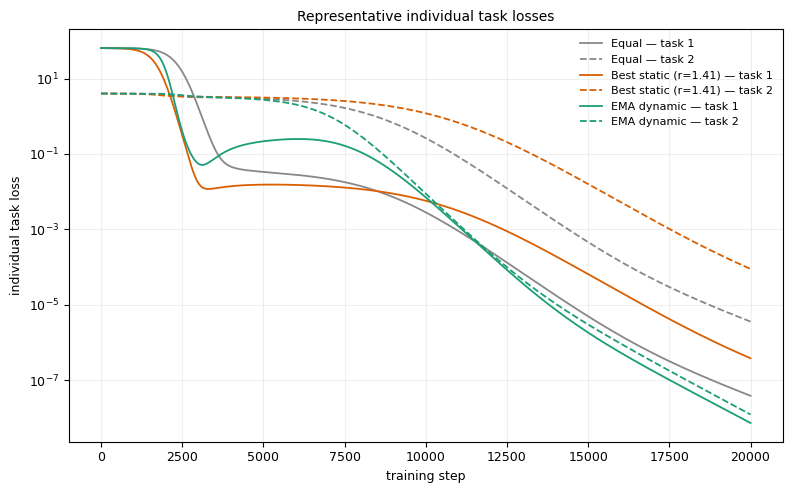

In [ ]:
# --------------------------------------------------
# Individual task-loss curves
fig_loss, ax = plt.subplots(figsize=(8, 5))

for result, color, method in [
    (equal_result, "#888888", "Equal"),
    (static_result, "#d95f02", f"Best static (r={best_ratio:.2f})"),
    (dynamic_result, "#1b9e77", "EMA dynamic"),
]:
    steps = np.arange(len(result["losses1"]))

    ax.plot(
        steps,
        result["losses1"],
        color=color,
        linewidth=1.3,
        label=f"{method} — task 1",
    )

    ax.plot(
        steps,
        result["losses2"],
        color=color,
        linestyle="--",
        linewidth=1.3,
        label=f"{method} — task 2",
    )

ax.set_yscale("log")
ax.set_xlabel("training step")
ax.set_ylabel("individual task loss")
ax.set_title("Representative individual task losses")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.2)

fig_loss.tight_layout()
fig_loss.savefig(
    "individual_task_losses.png",
    dpi=220,
    bbox_inches="tight",
)

plt.show()

## ALIGNED

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

from datasets import get_MTL_Tasks
from networks.linear_network import MTL_linearnetwork
from utils import MTL_get_lambda_balanced_STLex


# --------------------------------------------------
# Configuration
SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

TRAINING_STEPS = 70_000
LEARNING_RATE = 0.0002

IN_DIM = 5
HIDDEN_DIM = 2
OUT_DIM_1 = 1
OUT_DIM_2 = 1
BATCH_SIZE = 100

ALIGNMENT_FACTOR = 0.5
ALPHA_1 = 1.0
ALPHA_2 = 2.0

BETA = 0.4
EPS = 1e-8
WARMUP_STEPS = 20


# --------------------------------------------------
# One aligned experiment
def run_aligned_case(weighting_mode, seed):
    random.seed(seed)
    np.random.seed(seed)

    X, Y1, Y2 = get_MTL_Tasks(
        BATCH_SIZE,
        IN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        alpha_scales=(ALPHA_1, ALPHA_2),
        alignment_factor=ALIGNMENT_FACTOR,
        seed=seed,
    )

    init_ws, init_w1, init_w2 = MTL_get_lambda_balanced_STLex(
        0,
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        sigma_weights=0.0001,
    )

    model = MTL_linearnetwork(
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        init_ws=init_ws.copy(),
        init_w1=init_w1.copy(),
        init_w2=init_w2.copy(),
    )

    (
        wslist,
        w1list,
        w2list,
        losses1,
        losses2,
        cossim,
        gradmag1,
        gradmag2,
    ) = model.trainMTL(
        X.T,
        Y1,
        Y2,
        TRAINING_STEPS,
        LEARNING_RATE,
        trackgradients=True,
        save_weight_history=True,
        weighting_mode=weighting_mode,
        beta=BETA,
        eps=EPS,
        warmup_steps=WARMUP_STEPS,
    )

    losses1 = np.asarray(losses1, dtype=float)
    losses2 = np.asarray(losses2, dtype=float)

    return {
        "losses1": losses1,
        "losses2": losses2,
        "combined_loss": 0.5 * (losses1 + losses2),
        "w1": np.asarray(model.taskweight1_history, dtype=float),
        "w2": np.asarray(model.taskweight2_history, dtype=float),
        "cossim": np.asarray(cossim, dtype=float),
        "gradmag1": np.asarray(gradmag1, dtype=float),
        "gradmag2": np.asarray(gradmag2, dtype=float),
        "wslist": wslist,
        "w1list": w1list,
        "w2list": w2list,
    }


# --------------------------------------------------
# Run equal weighting and dynamic weighting
results = {
    "Equal": [],
    "Dynamic": [],
}

for seed in SEEDS:
    print(f"Running seed {seed}")

    results["Equal"].append(
        run_aligned_case(
            weighting_mode="none",
            seed=seed,
        )
    )

    results["Dynamic"].append(
        run_aligned_case(
            weighting_mode="ema_relative",
            seed=seed,
        )
    )

print("Finished fully aligned experiment.")


# --------------------------------------------------
# Convert seed results
def stack_metric(method, metric):
    return np.asarray([
        run[metric]
        for run in results[method]
    ])


steps = np.arange(TRAINING_STEPS)

equal_combined = stack_metric("Equal", "combined_loss")
dynamic_combined = stack_metric("Dynamic", "combined_loss")

equal_task1 = stack_metric("Equal", "losses1")
equal_task2 = stack_metric("Equal", "losses2")

dynamic_task1 = stack_metric("Dynamic", "losses1")
dynamic_task2 = stack_metric("Dynamic", "losses2")

dynamic_w1 = stack_metric("Dynamic", "w1")
dynamic_w2 = stack_metric("Dynamic", "w2")

dynamic_cossim = stack_metric("Dynamic", "cossim")




Running seed 0
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
Running seed 1
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
Running seed 2
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
Running seed 3
diffinitfunv [[-1.69406589e-20 -1.35525272e-20]
 [-1.35525272e-20  0.00000000e+00]]
diffinitfunv [[-1.69406589e-20 -1.35525272e-20]
 [-1.35525272e-20  0.00000000e+00]]
Running seed 4
diffinitfunv [[ 7.83505476e-21 -5.08219768e-21]
 [-5.08219768e-21  2.71050543e-20]]
diffinitfunv [[ 7.83505476e-21 -5.08219768e-21]
 [-5.08219768e-21  2.71050543e-20]]
Running seed 5
diffinitfunv [[ 8.97854924e-20 -1.01643954e-20]
 [-1.01643954e-20  2.7

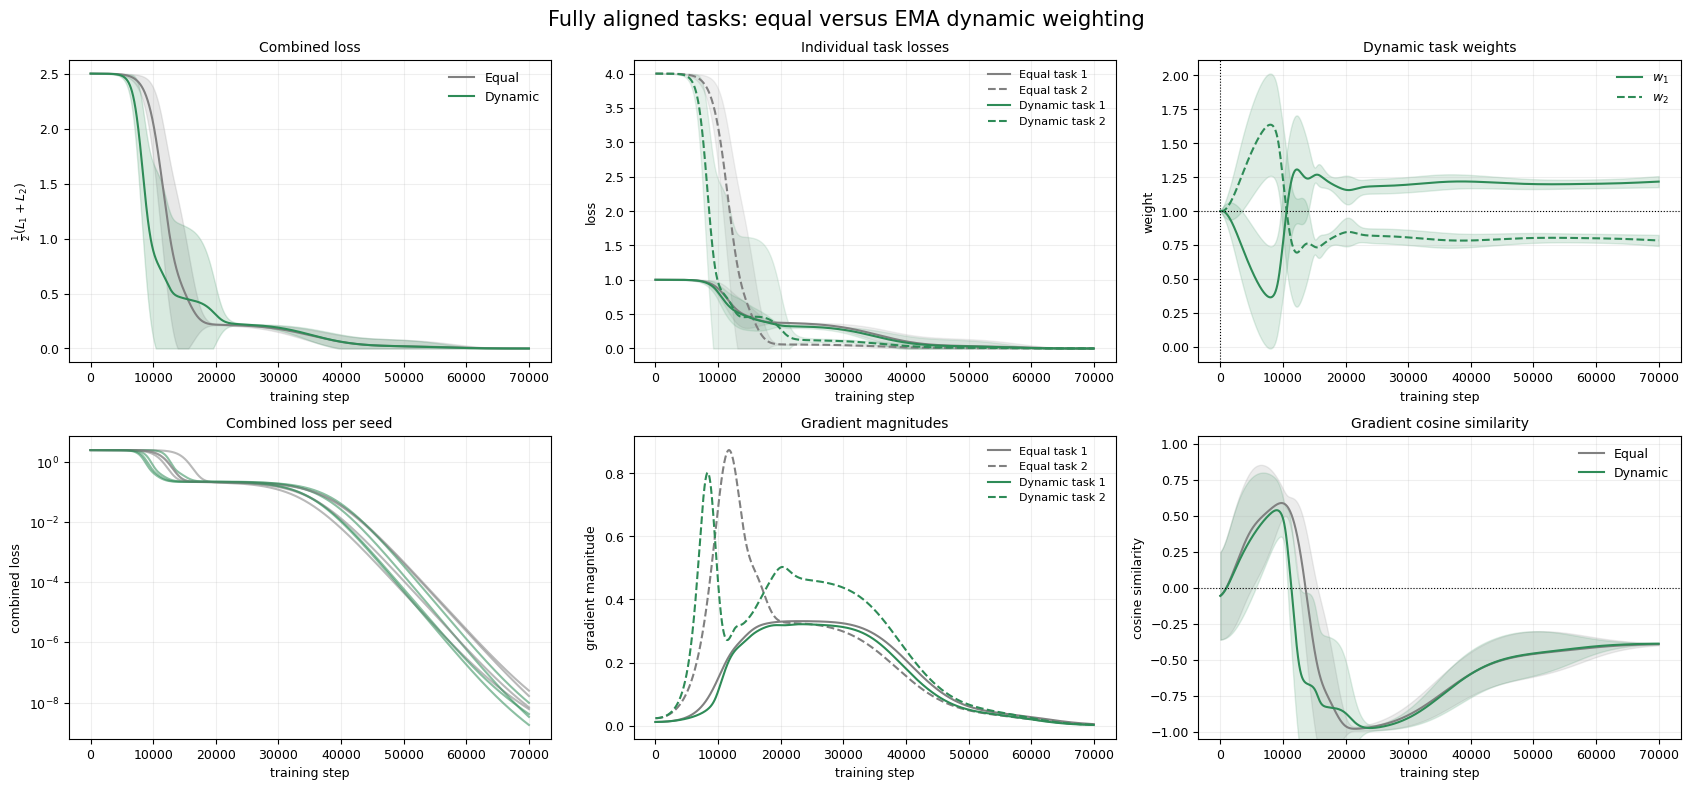

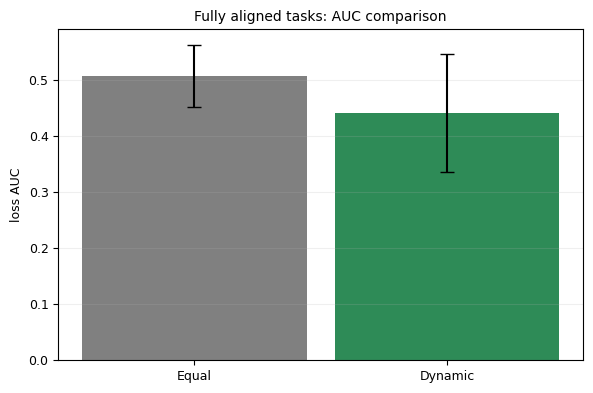

Equal AUC:   0.506208 ± 0.0554235
Dynamic AUC: 0.440985 ± 0.105411


In [ ]:
# --------------------------------------------------
# Plot summary
fig, axes = plt.subplots(2, 3, figsize=(17, 8))


# Combined losses
ax = axes[0, 0]

for values, color, label in [
    (equal_combined, "gray", "Equal"),
    (dynamic_combined, "seagreen", "Dynamic"),
]:
    mean = values.mean(axis=0)
    std = values.std(axis=0)

    ax.plot(steps, mean, color=color, label=label)
    ax.fill_between(
        steps,
        np.maximum(mean - std, 1e-12),
        mean + std,
        color=color,
        alpha=0.18,
    )

#ax.set_yscale("log")
ax.set_title("Combined loss")
ax.set_xlabel("training step")
ax.set_ylabel(r"$\frac{1}{2}(L_1+L_2)$")
ax.legend(frameon=False)
ax.grid(alpha=0.2)


# Individual task losses
ax = axes[0, 1]

for values, color, linestyle, label in [
    (equal_task1, "gray", "-", "Equal task 1"),
    (equal_task2, "gray", "--", "Equal task 2"),
    (dynamic_task1, "seagreen", "-", "Dynamic task 1"),
    (dynamic_task2, "seagreen", "--", "Dynamic task 2"),
]:
    mean = values.mean(axis=0)
    std = values.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=color,
        linestyle=linestyle,
        label=label,
    )

    ax.fill_between(
        steps,
        np.maximum(mean - std, 1e-12),
        mean + std,
        color=color,
        alpha=0.12,
    )

#ax.set_yscale("log")
ax.set_title("Individual task losses")
ax.set_xlabel("training step")
ax.set_ylabel("loss")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.2)


# Dynamic weights
ax = axes[0, 2]

for values, linestyle, label in [
    (dynamic_w1, "-", r"$w_1$"),
    (dynamic_w2, "--", r"$w_2$"),
]:
    mean = values.mean(axis=0)
    std = values.std(axis=0)

    ax.plot(
        steps,
        mean,
        color="seagreen",
        linestyle=linestyle,
        label=label,
    )

    ax.fill_between(
        steps,
        mean - std,
        mean + std,
        color="seagreen",
        alpha=0.15,
    )

ax.axhline(1.0, color="black", linestyle=":", linewidth=0.8)
ax.axvline(WARMUP_STEPS, color="black", linestyle=":", linewidth=0.8)

ax.set_title("Dynamic task weights")
ax.set_xlabel("training step")
ax.set_ylabel("weight")
ax.legend(frameon=False)
ax.grid(alpha=0.2)


# Per-seed combined losses
ax = axes[1, 0]

for seed_index, seed in enumerate(SEEDS):
    ax.plot(
        steps,
        equal_combined[seed_index],
        color="gray",
        alpha=0.55,
    )

    ax.plot(
        steps,
        dynamic_combined[seed_index],
        color="seagreen",
        alpha=0.55,
    )

ax.set_yscale("log")
ax.set_title("Combined loss per seed")
ax.set_xlabel("training step")
ax.set_ylabel("combined loss")
ax.grid(alpha=0.2)


# Gradient magnitudes
ax = axes[1, 1]

for method, color in [
    ("Equal", "gray"),
    ("Dynamic", "seagreen"),
]:
    gradmag1 = stack_metric(method, "gradmag1")
    gradmag2 = stack_metric(method, "gradmag2")

    ax.plot(
        steps,
        gradmag1.mean(axis=0),
        color=color,
        label=f"{method} task 1",
    )

    ax.plot(
        steps,
        gradmag2.mean(axis=0),
        color=color,
        linestyle="--",
        label=f"{method} task 2",
    )

#ax.set_yscale("log")
ax.set_title("Gradient magnitudes")
ax.set_xlabel("training step")
ax.set_ylabel("gradient magnitude")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.2)


# Cosine similarity
ax = axes[1, 2]

for method, color in [
    ("Equal", "gray"),
    ("Dynamic", "seagreen"),
]:
    cossim = stack_metric(method, "cossim")
    mean = cossim.mean(axis=0)
    std = cossim.std(axis=0)

    ax.plot(steps, mean, color=color, label=method)
    ax.fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.15,
    )

ax.axhline(0.0, color="black", linestyle=":", linewidth=0.8)
ax.set_ylim(-1.05, 1.05)
ax.set_title("Gradient cosine similarity")
ax.set_xlabel("training step")
ax.set_ylabel("cosine similarity")
ax.legend(frameon=False)
ax.grid(alpha=0.2)


fig.suptitle(
    "Fully aligned tasks: equal versus EMA dynamic weighting",
    fontsize=15,
)

fig.tight_layout()
plt.show()


# --------------------------------------------------
# AUC comparison
equal_auc = np.asarray([
    np.mean(run["combined_loss"])
    for run in results["Equal"]
])

dynamic_auc = np.asarray([
    np.mean(run["combined_loss"])
    for run in results["Dynamic"]
])

plt.figure(figsize=(6, 4))

plt.bar(
    [-0.18, 0.18],
    [equal_auc.mean(), dynamic_auc.mean()],
    width=0.32,
    yerr=[equal_auc.std(), dynamic_auc.std()],
    capsize=5,
    color=["gray", "seagreen"],
)

plt.xticks([-0.18, 0.18], ["Equal", "Dynamic"])
plt.ylabel("loss AUC")
plt.title("Fully aligned tasks: AUC comparison")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Equal AUC:   {equal_auc.mean():.6g} ± {equal_auc.std():.6g}"
)
print(
    f"Dynamic AUC: {dynamic_auc.mean():.6g} ± {dynamic_auc.std():.6g}"
)

In [ ]:
equal_auc = np.asarray([
    np.mean(run["combined_loss"])
    for run in results["Equal"]
])

dynamic_auc = np.asarray([
    np.mean(run["combined_loss"])
    for run in results["Dynamic"]
])

improvement = 100 * (equal_auc - dynamic_auc) / equal_auc

print("Per-seed improvement:")
for seed, value in zip(SEEDS, improvement):
    print(f"seed {seed}: {value:.3f}%")

mean_improvement = improvement.mean()
std_improvement = improvement.std(ddof=1)

# 95% t-interval for 10 seeds, 9 degrees of freedom
t_critical = 2.262
standard_error = std_improvement / np.sqrt(len(SEEDS))

ci_low = mean_improvement - t_critical * standard_error
ci_high = mean_improvement + t_critical * standard_error

print(f"\nMean improvement: {mean_improvement:.3f}%")
print(f"Std: {std_improvement:.3f}%")
print(f"95% CI: [{ci_low:.3f}%, {ci_high:.3f}%]")

Per-seed improvement:
seed 0: 12.050%
seed 1: 18.743%
seed 2: 14.629%
seed 3: 17.178%

Mean improvement: 13.793%
Std: 11.168%
95% CI: [1.162%, 26.424%]


Per-seed DWA improvement (%):
seed 0: 12.050%
seed 1: 18.743%
seed 2: 14.629%
seed 3: 17.178%

Mean improvement: 13.793%
Std improvement:  11.168%


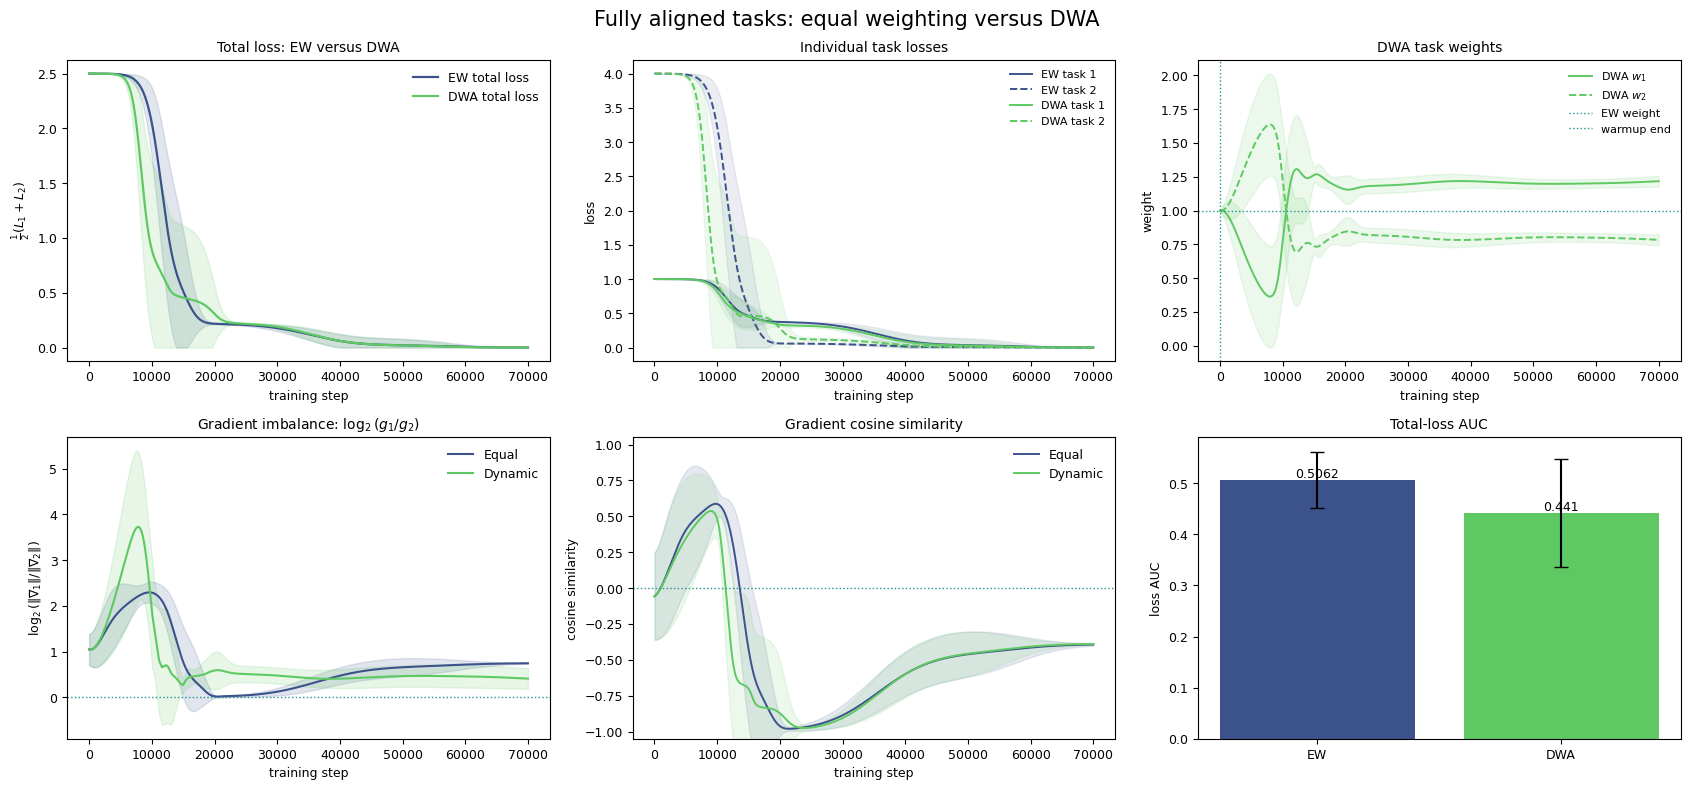

In [ ]:


def stack_metric(method, metric):
    return np.asarray([
        run[metric]
        for run in results[method]
    ])


equal_color = plt.get_cmap("viridis")(0.25)
dynamic_color = plt.get_cmap("viridis")(0.75)

steps = np.arange(
    len(results["Equal"][0]["combined_loss"])
)

equal_combined = stack_metric("Equal", "combined_loss")
dynamic_combined = stack_metric("Dynamic", "combined_loss")

equal_task1 = stack_metric("Equal", "losses1")
equal_task2 = stack_metric("Equal", "losses2")

dynamic_task1 = stack_metric("Dynamic", "losses1")
dynamic_task2 = stack_metric("Dynamic", "losses2")

dynamic_w1 = stack_metric("Dynamic", "w1")
dynamic_w2 = stack_metric("Dynamic", "w2")


fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 8),
)


# --------------------------------------------------
# Total loss: EW versus DWA
ax = axes[0, 0]

for values, color, label in [
    (equal_combined, equal_color, "EW total loss"),
    (dynamic_combined, dynamic_color, "DWA total loss"),
]:
    mean = values.mean(axis=0)
    std = values.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=color,
        linewidth=1.6,
        label=label,
    )

    ax.fill_between(
        steps,
        np.maximum(mean - std, 1e-12),
        mean + std,
        color=color,
        alpha=0.15,
    )


ax.set_title("Total loss: EW versus DWA")
ax.set_xlabel("training step")
ax.set_ylabel(r"$\frac{1}{2}(L_1+L_2)$")
ax.legend(frameon=False)


# --------------------------------------------------
# Individual task losses
ax = axes[0, 1]

for values, color, linestyle, label in [
    (equal_task1, equal_color, "-", "EW task 1"),
    (equal_task2, equal_color, "--", "EW task 2"),
    (dynamic_task1, dynamic_color, "-", "DWA task 1"),
    (dynamic_task2, dynamic_color, "--", "DWA task 2"),
]:
    mean = values.mean(axis=0)
    std = values.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=color,
        linestyle=linestyle,
        linewidth=1.4,
        label=label,
    )

    ax.fill_between(
        steps,
        np.maximum(mean - std, 1e-12),
        mean + std,
        color=color,
        alpha=0.10,
    )


ax.set_title("Individual task losses")
ax.set_xlabel("training step")
ax.set_ylabel("loss")
ax.legend(frameon=False, fontsize=8)


# --------------------------------------------------
# DWA task weights
ax = axes[0, 2]

for values, linestyle, label in [
    (dynamic_w1, "-", r"DWA $w_1$"),
    (dynamic_w2, "--", r"DWA $w_2$"),
]:
    mean = values.mean(axis=0)
    std = values.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=dynamic_color,
        linestyle=linestyle,
        linewidth=1.4,
        label=label,
    )

    ax.fill_between(
        steps,
        mean - std,
        mean + std,
        color=dynamic_color,
        alpha=0.12,
    )

ax.axhline(
    1.0,
    color=plt.get_cmap("viridis")(0.5),
    linestyle=":",
    linewidth=1.0,
    label="EW weight",
)

ax.axvline(
    WARMUP_STEPS,
    color=plt.get_cmap("viridis")(0.5),
    linestyle=":",
    linewidth=1.0,
    label="warmup end",
)

ax.set_title("DWA task weights")
ax.set_xlabel("training step")
ax.set_ylabel("weight")
ax.legend(frameon=False, fontsize=8)


# --------------------------------------------------
# Gradient magnitudes
# --------------------------------------------------
# Gradient-magnitude imbalance
#
# log2(g1 / g2) = 0  -> balanced
# log2(g1 / g2) > 0  -> task 1 has larger gradients
# log2(g1 / g2) < 0  -> task 2 has larger gradients

ax = axes[1, 0]

for method, color in [
    ("Equal", equal_color),
    ("Dynamic", dynamic_color),
]:
    gradmag1 = stack_metric(method, "gradmag1")
    gradmag2 = stack_metric(method, "gradmag2")

    imbalance = np.log2(
        (gradmag1 + EPS) / (gradmag2 + EPS)
    )
    absolute_imbalance = np.abs(
    np.log2((gradmag1 + EPS) / (gradmag2 + EPS))
)
    mean = absolute_imbalance.mean(axis=0)
    std = absolute_imbalance.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=color,
        linewidth=1.5,
        label=method,
    )

    ax.fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.15,
    )

ax.axhline(
    0.0,
    color=plt.get_cmap("viridis")(0.5),
    linestyle=":",
    linewidth=1.0,
)

ax.set_title(r"Gradient imbalance: $\log_2(g_1/g_2)$")
ax.set_xlabel("training step")
ax.set_ylabel(r"$\log_2(\|\nabla_1\|/\|\nabla_2\|)$")
ax.legend(frameon=False)


# --------------------------------------------------
# Gradient cosine similarity
ax = axes[1, 1]

for method, color in [
    ("Equal", equal_color),
    ("Dynamic", dynamic_color),
]:
    cossim = stack_metric(method, "cossim")
    mean = cossim.mean(axis=0)
    std = cossim.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=color,
        linewidth=1.4,
        label=method,
    )

    ax.fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.12,
    )

ax.axhline(
    0.0,
    color=plt.get_cmap("viridis")(0.5),
    linestyle=":",
    linewidth=1.0,
)

ax.set_ylim(-1.05, 1.05)
ax.set_title("Gradient cosine similarity")
ax.set_xlabel("training step")
ax.set_ylabel("cosine similarity")
ax.legend(frameon=False)


# --------------------------------------------------
# AUC comparison
ax = axes[1, 2]

equal_auc = np.mean(equal_combined, axis=1)
dynamic_auc = np.mean(dynamic_combined, axis=1)
# Positive value means DWA is better
improvement = 100.0 * (equal_auc - dynamic_auc) / equal_auc

print("Per-seed DWA improvement (%):")

for seed, value in zip(SEEDS, improvement):
    print(f"seed {seed}: {value:.3f}%")

print()
print(f"Mean improvement: {improvement.mean():.3f}%")
print(f"Std improvement:  {improvement.std(ddof=1):.3f}%")
auc_means = [
    equal_auc.mean(),
    dynamic_auc.mean(),
]

auc_stds = [
    equal_auc.std(),
    dynamic_auc.std(),
]

bars = ax.bar(
    [0, 1],
    auc_means,
    yerr=auc_stds,
    capsize=5,
    color=[equal_color, dynamic_color],
)

ax.set_xticks([0, 1], ["EW", "DWA"])
ax.set_ylabel("loss AUC")
ax.set_title("Total-loss AUC")
ax.set_ylim(bottom=0)

for bar, value in zip(bars, auc_means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.4g}",
        ha="center",
        va="bottom",
    )


fig.suptitle(
    "Fully aligned tasks: equal weighting versus DWA",
    fontsize=15,
)

fig.tight_layout()
plt.show()

In [ ]:
equal_auc = np.asarray([
    np.mean(run["combined_loss"])
    for run in results["Equal"]
])

dynamic_auc = np.asarray([
    np.mean(run["combined_loss"])
    for run in results["Dynamic"]
])

improvement = 100 * (equal_auc - dynamic_auc) / equal_auc

for seed, value in zip(SEEDS, improvement):
    print(f"seed {seed}: {value:.3f}%")

print(f"Mean: {improvement.mean():.3f}%")
print(f"Std:  {improvement.std(ddof=1):.3f}%")

seed 0: 12.050%
seed 1: 18.743%
seed 2: 14.629%
seed 3: 17.178%
Mean: 13.793%
Std:  11.168%


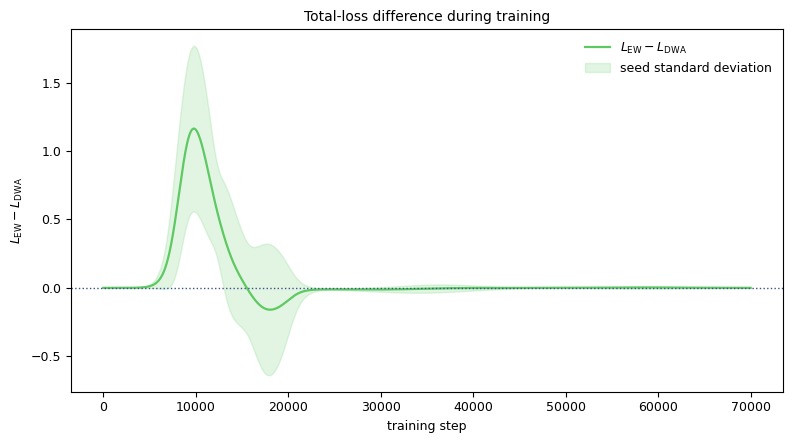

In [ ]:
# --------------------------------------------------
# EW total loss minus DWA total loss
#
# Positive values: DWA has lower loss
# Negative values: EW has lower loss

loss_difference = equal_combined - dynamic_combined

difference_mean = loss_difference.mean(axis=0)
difference_std = loss_difference.std(axis=0)

plt.figure(figsize=(8, 4.5))

plt.plot(
    steps,
    difference_mean,
    color=plt.get_cmap("viridis")(0.75),
    linewidth=1.6,
    label=r"$L_{\mathrm{EW}} - L_{\mathrm{DWA}}$",
)

plt.fill_between(
    steps,
    difference_mean - difference_std,
    difference_mean + difference_std,
    color=plt.get_cmap("viridis")(0.75),
    alpha=0.18,
    label="seed standard deviation",
)

plt.axhline(
    0.0,
    color=plt.get_cmap("viridis")(0.25),
    linestyle=":",
    linewidth=1.0,
)

plt.xlabel("training step")
plt.ylabel(r"$L_{\mathrm{EW}} - L_{\mathrm{DWA}}$")
plt.title("Total-loss difference during training")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## BETA CHECK

diffinitfunv [[-6.93889390e-18  4.77048956e-18]
 [ 4.77048956e-18 -4.77048956e-18]]
diffinitfunv [[-1.73472348e-18 -3.46944695e-18]
 [-3.46944695e-18  3.46944695e-18]]
diffinitfunv [[5.82758668e-18 2.38524478e-18]
 [2.38524478e-18 5.20417043e-18]]
diffinitfunv [[ 1.30104261e-18  8.67361738e-19]
 [ 8.67361738e-19 -1.73472348e-18]]
Running beta=0.99
diffinitfunv [[-6.93889390e-18  4.77048956e-18]
 [ 4.77048956e-18 -4.77048956e-18]]
diffinitfunv [[-1.73472348e-18 -3.46944695e-18]
 [-3.46944695e-18  3.46944695e-18]]
diffinitfunv [[5.82758668e-18 2.38524478e-18]
 [2.38524478e-18 5.20417043e-18]]
diffinitfunv [[ 1.30104261e-18  8.67361738e-19]
 [ 8.67361738e-19 -1.73472348e-18]]
Running beta=0.99
diffinitfunv [[-6.93889390e-18  4.77048956e-18]
 [ 4.77048956e-18 -4.77048956e-18]]
diffinitfunv [[-1.73472348e-18 -3.46944695e-18]
 [-3.46944695e-18  3.46944695e-18]]
diffinitfunv [[5.82758668e-18 2.38524478e-18]
 [2.38524478e-18 5.20417043e-18]]
diffinitfunv [[ 1.30104261e-18  8.67361738e-19]
 [ 8

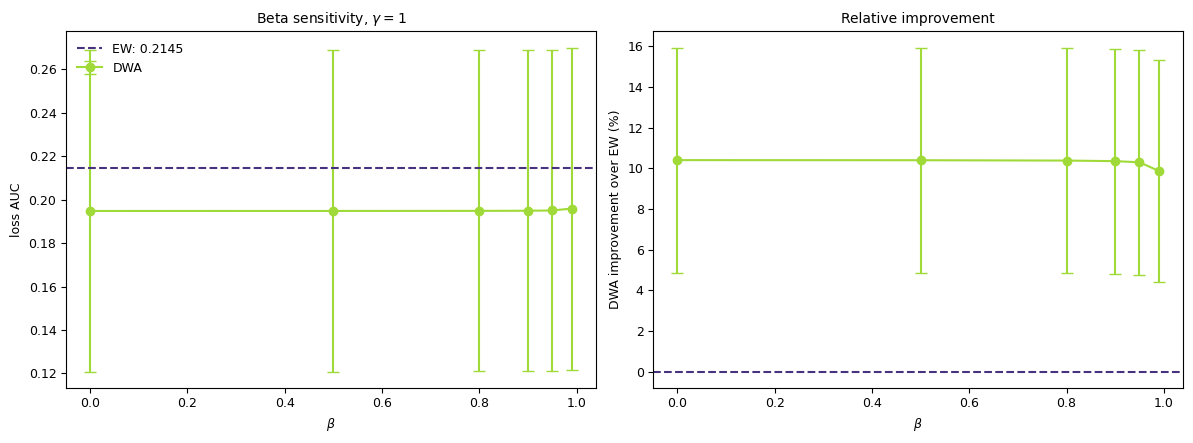

beta= 0.0: AUC=0.194801 +/- 0.073897, improvement=10.397% +/- 5.537%
beta= 0.5: AUC=0.194813 +/- 0.073899, improvement=10.392% +/- 5.536%
beta= 0.8: AUC=0.194849 +/- 0.073907, improvement=10.374% +/- 5.534%
beta= 0.9: AUC=0.194908 +/- 0.073919, improvement=10.346% +/- 5.531%
beta=0.95: AUC=0.195026 +/- 0.073944, improvement=10.290% +/- 5.524%
beta=0.99: AUC=0.195919 +/- 0.074112, improvement=9.864% +/- 5.466%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# -----------------------------------------------
# Beta sweep for gamma/alignment = 0.5
GAMMA = 1
BETAS = [0.0, 0.5, 0.8, 0.9, 0.95, 0.99]

# Use existing SEEDS, or define them here
SEEDS = [0, 1, 2, 3]

ALPHA_1 = 1.0
ALPHA_2 = 2.0


# -----------------------------------------------
# Equal baseline, fixed across all beta values
equal_runs = {}

for seed in SEEDS:
    equal_runs[seed] = run_case(
        alignment_factor=GAMMA,
        alpha_1=ALPHA_1,
        alpha_2=ALPHA_2,
        weighting_mode="none",
        seed=seed,
    )


# -----------------------------------------------
# Dynamic runs for each beta
beta_results = {}

for beta_value in BETAS:
    print(f"Running beta={beta}")

    # run_case() reads EMA_BETA from the global configuration
    EMA_BETA = beta_value

    beta_results[beta_value] = []

    for seed in SEEDS:
        result = run_case(
            alignment_factor=GAMMA,
            alpha_1=ALPHA_1,
            alpha_2=ALPHA_2,
            weighting_mode="ema_relative",
            seed=seed,
            beta=beta_value
        )

        beta_results[beta_value].append(result)


# -----------------------------------------------
# Calculate AUC and improvement relative to EW
equal_auc = np.asarray([
    np.mean(equal_runs[seed]["combined_loss"])
    for seed in SEEDS
])

beta_auc_mean = []
beta_auc_std = []
beta_improvement_mean = []
beta_improvement_std = []

for beta_value in BETAS:
    dynamic_auc = np.asarray([
        np.mean(run["combined_loss"])
        for run in beta_results[beta_value]
    ])

    improvement = 100.0 * (equal_auc - dynamic_auc) / equal_auc

    beta_auc_mean.append(dynamic_auc.mean())
    beta_auc_std.append(dynamic_auc.std(ddof=1))

    beta_improvement_mean.append(improvement.mean())
    beta_improvement_std.append(improvement.std(ddof=1))


# -----------------------------------------------
# Plot beta sensitivity
cmap = plt.colormaps["viridis"].resampled(8)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# AUC
axes[0].errorbar(
    BETAS,
    beta_auc_mean,
    yerr=beta_auc_std,
    marker="o",
    color=cmap(6),
    capsize=4,
    label="DWA",
)

axes[0].axhline(
    equal_auc.mean(),
    color=cmap(1),
    linestyle="--",
    label=f"EW: {equal_auc.mean():.4f}",
)

axes[0].set_xlabel(r"$\beta$")
axes[0].set_ylabel("loss AUC")
axes[0].set_title(rf"Beta sensitivity, $\gamma={GAMMA}$")
axes[0].legend(frameon=False)

# Improvement
axes[1].errorbar(
    BETAS,
    beta_improvement_mean,
    yerr=beta_improvement_std,
    marker="o",
    color=cmap(6),
    capsize=4,
)

axes[1].axhline(
    0.0,
    color=cmap(1),
    linestyle="--",
)

axes[1].set_xlabel(r"$\beta$")
axes[1].set_ylabel("DWA improvement over EW (%)")
axes[1].set_title("Relative improvement")
    
fig.tight_layout()
plt.show()


# -----------------------------------------------
# Print results
for beta, auc_mean, auc_std, imp_mean, imp_std in zip(
    BETAS,
    beta_auc_mean,
    beta_auc_std,
    beta_improvement_mean,
    beta_improvement_std,
):
    print(
        f"beta={beta:>4}: "
        f"AUC={auc_mean:.6f} +/- {auc_std:.6f}, "
        f"improvement={imp_mean:.3f}% +/- {imp_std:.3f}%"
    )

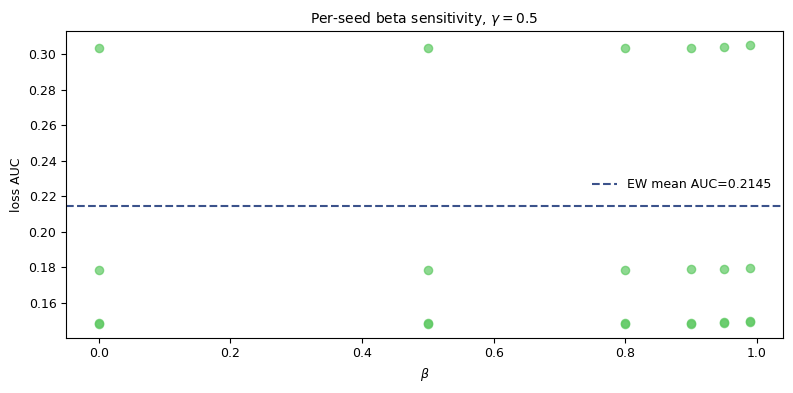

In [ ]:
plt.figure(figsize=(8, 4))

for beta in BETAS:
    dynamic_auc = np.asarray([
        np.mean(run["combined_loss"])
        for run in beta_results[beta]
    ])

    x = np.full(len(dynamic_auc), beta)

    plt.scatter(
        x,
        dynamic_auc,
        color=dynamic_color,
        alpha=0.7,
        s=35,
    )

plt.axhline(
    equal_auc.mean(),
    color=equal_color,
    linestyle="--",
    label=f"EW mean AUC={equal_auc.mean():.4f}",
)

plt.xlabel(r"$\beta$")
plt.ylabel("loss AUC")
plt.title(r"Per-seed beta sensitivity, $\gamma=0.5$")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
reference_beta = BETAS[0]

for beta_value in BETAS[1:]:
    reference_weights = np.asarray([
        run["w1"]
        for run in beta_results[reference_beta]
    ])

    current_weights = np.asarray([
        run["w1"]
        for run in beta_results[beta_value]
    ])

    max_weight_difference = np.max(
        np.abs(reference_weights - current_weights)
    )

    reference_auc = np.asarray([
        np.mean(run["combined_loss"])
        for run in beta_results[reference_beta]
    ])

    current_auc = np.asarray([
        np.mean(run["combined_loss"])
        for run in beta_results[beta_value]
    ])

    max_auc_difference = np.max(
        np.abs(reference_auc - current_auc)
    )

    print(
        f"beta {reference_beta} vs {beta_value}: "
        f"max weight difference={max_weight_difference:.3e}, "
        f"max AUC difference={max_auc_difference:.3e}"
    )

beta 0.0 vs 0.5: max weight difference=4.100e-04, max AUC difference=1.608e-05
beta 0.0 vs 0.8: max weight difference=1.641e-03, max AUC difference=6.415e-05
beta 0.0 vs 0.9: max weight difference=3.695e-03, max AUC difference=1.437e-04
beta 0.0 vs 0.95: max weight difference=7.815e-03, max AUC difference=3.008e-04
beta 0.0 vs 0.99: max weight difference=4.109e-02, max AUC difference=1.464e-03


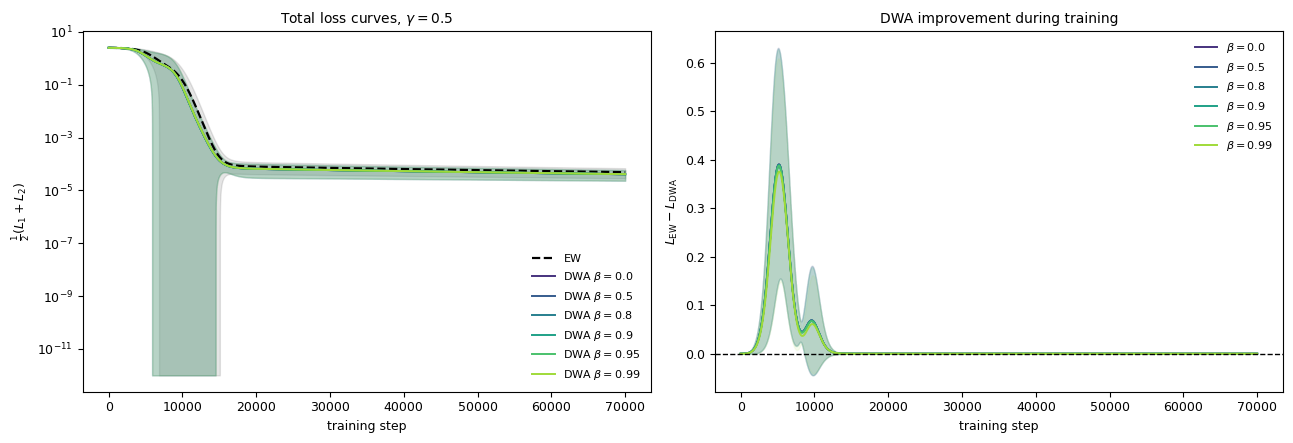

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


cmap = plt.colormaps["viridis"].resampled(len(BETAS) + 2)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)


# --------------------------------------------------
# Total loss curves
ax = axes[0]

equal_runs = [
    run["combined_loss"]
    for run in equal_runs.values()
]

equal_runs = np.asarray(equal_runs)
equal_mean = equal_runs.mean(axis=0)
equal_std = equal_runs.std(axis=0)

steps = np.arange(len(equal_mean))

ax.plot(
    steps,
    equal_mean,
    color="black",
    linestyle="--",
    linewidth=1.6,
    label="EW",
)

ax.fill_between(
    steps,
    np.maximum(equal_mean - equal_std, 1e-12),
    equal_mean + equal_std,
    color="black",
    alpha=0.10,
)

for index, beta_value in enumerate(BETAS):
    dynamic_runs = np.asarray([
        run["combined_loss"]
        for run in beta_results[beta_value]
    ])

    dynamic_mean = dynamic_runs.mean(axis=0)
    dynamic_std = dynamic_runs.std(axis=0)

    color = cmap(index + 1)

    ax.plot(
        steps,
        dynamic_mean,
        color=color,
        linewidth=1.4,
        label=rf"DWA $\beta={beta_value}$",
    )

    ax.fill_between(
        steps,
        np.maximum(dynamic_mean - dynamic_std, 1e-12),
        dynamic_mean + dynamic_std,
        color=color,
        alpha=0.08,
    )

ax.set_yscale("log")
ax.set_xlabel("training step")
ax.set_ylabel(r"$\frac{1}{2}(L_1+L_2)$")
ax.set_title(r"Total loss curves, $\gamma=0.5$")
ax.legend(frameon=False, fontsize=8)


# --------------------------------------------------
# Difference from EW
ax = axes[1]

for index, beta_value in enumerate(BETAS):
    dynamic_runs = np.asarray([
        run["combined_loss"]
        for run in beta_results[beta_value]
    ])

    difference = equal_runs - dynamic_runs
    difference_mean = difference.mean(axis=0)
    difference_std = difference.std(axis=0)

    color = cmap(index + 1)

    ax.plot(
        steps,
        difference_mean,
        color=color,
        linewidth=1.4,
        label=rf"$\beta={beta_value}$",
    )

    ax.fill_between(
        steps,
        difference_mean - difference_std,
        difference_mean + difference_std,
        color=color,
        alpha=0.08,
    )

ax.axhline(
    0.0,
    color="black",
    linestyle="--",
    linewidth=1.0,
)

ax.set_xlabel("training step")
ax.set_ylabel(r"$L_{\mathrm{EW}}-L_{\mathrm{DWA}}$")
ax.set_title("DWA improvement during training")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
plt.show()

ValueError: x and y must have same first dimension, but have shapes (70000,) and (20000,)

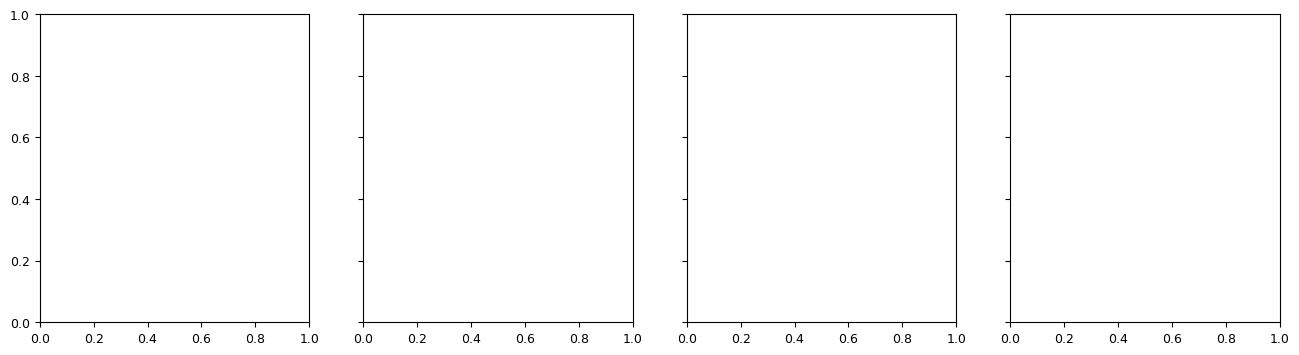

In [ ]:
fig, axes = plt.subplots(
    1,
    len(SEEDS),
    figsize=(16, 4),
    sharey=True,
)

cmap = plt.colormaps["viridis"].resampled(len(BETAS) + 2)

for seed_index, seed in enumerate(SEEDS):
    ax = axes[seed_index]

    # Equal baseline
    ax.plot(
        steps,
        equal_seed_losses[seed_index],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="EW",
    )

    # All beta values for this seed
    for beta_index, beta_value in enumerate(BETAS):
        dynamic_loss = beta_results[beta_value][seed_index]["combined_loss"]

        ax.plot(
            steps,
            dynamic_loss,
            color=cmap(beta_index + 1),
            linewidth=1.2,
            label=rf"$\beta={beta_value}$",
        )

    ax.set_yscale("log")
    ax.set_title(f"Seed {seed}")
    ax.set_xlabel("training step")

    if seed_index == 0:
        ax.set_ylabel(r"$\frac{1}{2}(L_1+L_2)$")

    if seed_index == 0:
        ax.legend(frameon=False, fontsize=8)

fig.suptitle(
    r"Beta sensitivity by seed, $\gamma=0.5$",
    fontsize=14,
)

fig.tight_layout()
plt.show()

## Three method sweep

In [ ]:
import csv
from pathlib import Path

CONFLICT_STRENGTH = 1.0
SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

TRAINING_STEPS = 70_000
LEARNING_RATE = 0.0002

IN_DIM = 5
HIDDEN_DIM = 2
OUT_DIM_1 = 1
OUT_DIM_2 = 1
BATCH_SIZE = 100

ALIGNMENT_FACTOR = 0.5
ALPHA_1 = 1.0
ALPHA_2 = 1.0

BETA = 0.4
EPS = 1e-8
WARMUP_STEPS = 20
METHODS = {
    "EW": {
        "weighting_mode": "none",
        "gradient_surgery": "none",
    },
    "DWA": {
        "weighting_mode": "ema_relative",
        "gradient_surgery": "none",
    },
    "Conflict-DWA": {
        "weighting_mode": "conflict_ema",
        "gradient_surgery": "none",
        "conflict_strength": 1.0,
    },
    "Conflict-PCGrad": {
        "weighting_mode": "none",
        "gradient_surgery": "pcgrad",
    },
}


def run_aligned_case(
    weighting_mode,
    seed,
    gradient_surgery="none",
    conflict_strength=1.0,
):
    random.seed(seed)
    np.random.seed(seed)

    X, Y1, Y2 = get_MTL_Tasks(
        BATCH_SIZE,
        IN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        alpha_scales=(ALPHA_1, ALPHA_2),
        alignment_factor=ALIGNMENT_FACTOR,
        seed=seed,
    )

    init_ws, init_w1, init_w2 = MTL_get_lambda_balanced_STLex(
        0,
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        sigma_weights=0.0001,
    )

    model = MTL_linearnetwork(
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        init_ws=init_ws.copy(),
        init_w1=init_w1.copy(),
        init_w2=init_w2.copy(),
    )

    (
        wslist,
        w1list,
        w2list,
        losses1,
        losses2,
        cossim,
        gradmag1,
        gradmag2,
    ) = model.trainMTL(
        X.T,
        Y1,
        Y2,
        TRAINING_STEPS,
        LEARNING_RATE,
        trackgradients=True,
        save_weight_history=True,
        weighting_mode=weighting_mode,
        gradient_surgery=gradient_surgery,
        beta=BETA,
        eps=EPS,
        warmup_steps=WARMUP_STEPS,
        conflict_strength=conflict_strength,
    )

    losses1 = np.asarray(losses1, dtype=float)
    losses2 = np.asarray(losses2, dtype=float)

    return {
        "losses1": losses1,
        "losses2": losses2,
        "combined_loss": 0.5 * (losses1 + losses2),
        "w1": np.asarray(model.taskweight1_history),
        "w2": np.asarray(model.taskweight2_history),
        "cossim": np.asarray(cossim),
        "postsurg_cossim": np.asarray(
            model.postsurg_cossim_history
        ),
        "gradmag1": np.asarray(gradmag1),
        "gradmag2": np.asarray(gradmag2),
        "conflict_score": np.asarray(
            getattr(
                model,
                "conflict_score_history",
                np.maximum(0.0, -np.asarray(cossim)),
            )
        ),
        "wslist": wslist,
        "w1list": w1list,
        "w2list": w2list,
    }


# --------------------------------------------------
# Run all three methods
results = {
    method_name: []
    for method_name in METHODS
}

for method_name, config in METHODS.items():
    for seed in SEEDS:
        print(f"Running {method_name}, seed={seed}")

        results[method_name].append(
            run_aligned_case(
                weighting_mode=config["weighting_mode"],
                gradient_surgery=config.get(
                    "gradient_surgery",
                    "none",
                ),
                conflict_strength=config.get(
                    "conflict_strength",
                    1.0,
                ),
                seed=seed,
            )
        )

Running EW, seed=0
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
Running EW, seed=1
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
Running EW, seed=2
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
Running EW, seed=3
diffinitfunv [[-1.69406589e-20 -1.35525272e-20]
 [-1.35525272e-20  0.00000000e+00]]
Running EW, seed=4
diffinitfunv [[ 7.83505476e-21 -5.08219768e-21]
 [-5.08219768e-21  2.71050543e-20]]
Running EW, seed=5
diffinitfunv [[ 8.97854924e-20 -1.01643954e-20]
 [-1.01643954e-20  2.71050543e-20]]
Running EW, seed=6
diffinitfunv [[-8.13151629e-20 -1.35525272e-20]
 [-1.35525272e-20  3.04931861e-20]]
Running EW, seed=7
diffinitfunv [[ 6.77626358e-20 -6.77626358e-20]
 [-6.77626358e-20  6.77626358e-20]]
Running EW, seed=8
diffinitfunv [[-1.35525272e-20  1.35525272e-20]
 [ 1.35525272e-20  3.38813179e-21]]
Running EW, seed=9
diffinitfunv [[-1.08420217e-19 -4.06575815e-20]
 [-4.0

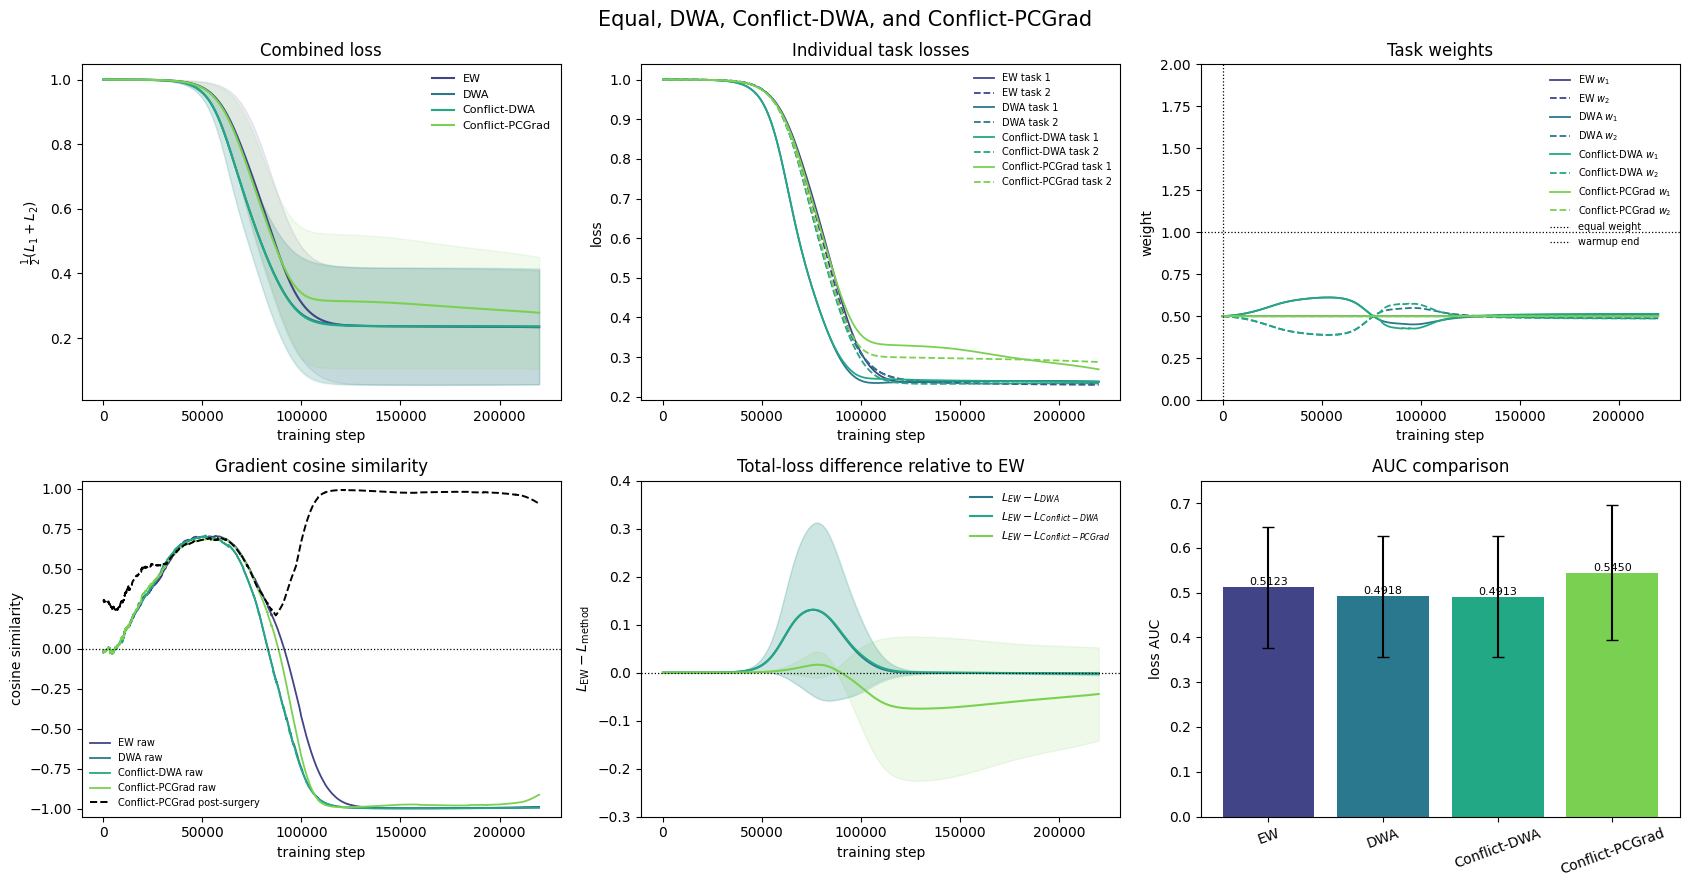

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


method_order = [
    "EW",
    "DWA",
    "Conflict-DWA",
    "Conflict-PCGrad",
]

cmap = plt.colormaps["viridis"].resampled(len(method_order) + 2)

method_colors = {
    method: cmap(index + 1)
    for index, method in enumerate(method_order)
}


def stack_metric(method, metric):
    return np.asarray([
        run[metric]
        for run in results[method]
    ])


steps = np.arange(
    len(results["EW"][0]["combined_loss"])
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 9),
)


# --------------------------------------------------
# 1. Combined loss
ax = axes[0, 0]

for method in method_order:
    values = stack_metric(method, "combined_loss")
    mean = values.mean(axis=0)
    std = values.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=method_colors[method],
        linewidth=1.5,
        label=method,
    )

    ax.fill_between(
        steps,
        np.maximum(mean - std, 1e-12),
        mean + std,
        color=method_colors[method],
        alpha=0.10,
    )


ax.set_title("Combined loss")
ax.set_xlabel("training step")
ax.set_ylabel(r"$\frac{1}{2}(L_1+L_2)$")
ax.legend(frameon=False, fontsize=8)


# --------------------------------------------------
# 2. Individual task losses
ax = axes[0, 1]

for method in method_order:
    task1 = stack_metric(method, "losses1").mean(axis=0)
    task2 = stack_metric(method, "losses2").mean(axis=0)

    ax.plot(
        steps,
        task1,
        color=method_colors[method],
        linewidth=1.3,
        label=f"{method} task 1",
    )

    ax.plot(
        steps,
        task2,
        color=method_colors[method],
        linestyle="--",
        linewidth=1.3,
        label=f"{method} task 2",
    )


ax.set_title("Individual task losses")
ax.set_xlabel("training step")
ax.set_ylabel("loss")
ax.legend(frameon=False, fontsize=7)


# --------------------------------------------------
# 3. Task weights
ax = axes[0, 2]

for method in method_order:
    weights1 = stack_metric(method, "w1")
    weights2 = stack_metric(method, "w2")

    ax.plot(
        steps,
        weights1.mean(axis=0),
        color=method_colors[method],
        linewidth=1.3,
        label=f"{method} $w_1$",
    )

    ax.plot(
        steps,
        weights2.mean(axis=0),
        color=method_colors[method],
        linestyle="--",
        linewidth=1.3,
        label=f"{method} $w_2$",
    )

ax.axhline(
    1.0,
    color="black",
    linestyle=":",
    linewidth=0.9,
    label="equal weight",
)

ax.axvline(
    WARMUP_STEPS,
    color="black",
    linestyle=":",
    linewidth=0.9,
    label="warmup end",
)
ax.set_ylim(0, 2)
ax.set_title("Task weights")
ax.set_xlabel("training step")
ax.set_ylabel("weight")
ax.legend(frameon=False, fontsize=7)


# --------------------------------------------------
# 4. Raw and post-surgery cosine similarity
ax = axes[1, 0]

for method in method_order:
    cossim = stack_metric(method, "cossim")

    ax.plot(
        steps,
        cossim.mean(axis=0),
        color=method_colors[method],
        linewidth=1.3,
        label=f"{method} raw",
    )

# Post-PCGrad cosine for the conflict-only method
if "postsurg_cossim" in results["Conflict-PCGrad"][0]:
    post_cossim = stack_metric(
        "Conflict-PCGrad",
        "postsurg_cossim",
    )

    ax.plot(
        steps,
        post_cossim.mean(axis=0),
        color="black",
        linestyle="--",
        linewidth=1.4,
        label="Conflict-PCGrad post-surgery",
    )

ax.axhline(
    0.0,
    color="black",
    linestyle=":",
    linewidth=0.9,
)

ax.set_ylim(-1.05, 1.05)
ax.set_title("Gradient cosine similarity")
ax.set_xlabel("training step")
ax.set_ylabel("cosine similarity")
ax.legend(frameon=False, fontsize=7)


# --------------------------------------------------
# --------------------------------------------------
# Total-loss difference relative to EW
#
# Positive values: comparison method has lower loss than EW
# Negative values: EW has lower loss

ax = axes[1, 1]

ew_losses = stack_metric("EW", "combined_loss")

for method in [
    "DWA",
    "Conflict-DWA",
    "Conflict-PCGrad",
]:
    method_losses = stack_metric(
        method,
        "combined_loss",
    )

    # Paired seed-wise difference
    difference = ew_losses - method_losses

    mean = difference.mean(axis=0)
    std = difference.std(axis=0)

    ax.plot(
        steps,
        mean,
        color=method_colors[method],
        linewidth=1.5,
        label=rf"$L_{{EW}}-L_{{{method}}}$",
    )

    ax.fill_between(
        steps,
        mean - std,
        mean + std,
        color=method_colors[method],
        alpha=0.12,
    )

ax.axhline(
    0.0,
    color="black",
    linestyle=":",
    linewidth=0.9,
)

ax.set_title("Total-loss difference relative to EW")
ax.set_xlabel("training step")
ax.set_ylim(-0.3, 0.4)
ax.set_ylabel(r"$L_{\mathrm{EW}}-L_{\mathrm{method}}$")
ax.legend(frameon=False, fontsize=8)


# --------------------------------------------------
# 6. AUC comparison
ax = axes[1, 2]

auc_means = []
auc_stds = []

for method in method_order:
    auc_values = np.asarray([
        np.mean(run["combined_loss"])
        for run in results[method]
    ])

    auc_means.append(auc_values.mean())
    auc_stds.append(auc_values.std(ddof=1))

x = np.arange(len(method_order))

bars = ax.bar(
    x,
    auc_means,
    yerr=auc_stds,
    capsize=4,
    color=[
        method_colors[method]
        for method in method_order
    ],
)

ax.set_xticks(
    x,
    ["EW", "DWA", "Conflict-DWA", "Conflict-PCGrad"],
    rotation=20,
)
ax.set_ylim(0, 0.75)
ax.set_ylabel("loss AUC")
ax.set_title("AUC comparison")

for bar, value in zip(bars, auc_means):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=8,
    )


fig.suptitle(
    "Equal, DWA, Conflict-DWA, and Conflict-PCGrad",
    fontsize=15,
)

fig.tight_layout()
plt.show()

In [ ]:
import pandas as pd

raw = pd.read_csv("continuous_alignment_imbalance_sweep.csv")

raw = raw[
    raw["log2_alpha1_over_alpha2"].eq(0)
].copy()

raw["improvement_pct"] = 100 * (
    raw["auc_ew"] - raw["auc_method"]
) / raw["auc_ew"]

per_seed = raw.pivot_table(
    index=["theta", "seed"],
    columns="method",
    values="improvement_pct",
)

display(per_seed.round(2))

method      Conflict-DWA  Conflict-PCGrad    DWA
theta seed                                      
0.00  0             4.74             4.58   3.06
      1             4.35             0.46   4.11
      2             6.15             0.13   6.14
      3             4.07             0.07   4.04
      4             8.03             0.79   7.99
      5             3.59             0.45   3.40
      6             3.63             4.26   1.82
      7             8.60             7.94   5.54
      8             2.24             1.07   1.88
      9             1.04             1.86   0.19
0.25  0             4.07             7.99   2.69
      1             0.39             3.10  -2.58
      2             2.71             3.62   0.99
      3             1.12             2.63  -1.41
      4             4.04             2.67   2.76
      5             1.98             2.71  -0.88
      6             2.90             7.95  -0.32
      7             2.14             8.61   0.61
      8             0.15             3.67   0.14
      9            -0.47             3.81  -3.45
0.50  0             9.10             7.79   8.77
      1             0.28             4.39  -0.16
      2             1.71             5.16   1.63
      3             0.65             4.22   0.37
      4             4.79             3.81   4.62
      5             6.37             4.84   5.72
      6             9.63             9.18   8.83
      7             0.64             9.09   0.60
      8             0.09             5.36  -0.10
      9            -0.21             4.87  -0.96
0.75  0            13.33             5.23  13.28
      1             0.94             2.87   0.89
      2             0.33             3.65   0.31
      3             0.07             2.89   0.06
      4             0.83             2.38   0.75
      5             9.63             3.95   9.55
      6            16.82             7.50  16.70
      7             0.00             1.03  -0.00
      8             0.26             4.46   0.23
      9             0.46             3.17   0.31
1.00  0            14.93             1.50  14.93
      1             2.21            -0.00   2.21
      2             0.16             0.70   0.16
      3             0.05             0.01   0.05
      4             0.71             0.00   0.71
      5            11.14             1.56  11.13
      6            18.58             4.79  18.55
      7             0.08             0.00   0.08
      8             0.26             2.63   0.26
      9             1.10            -0.00   1.10

In [ ]:
for method in [
    "DWA",
    "Conflict-DWA",
    "Conflict-PCGrad",
]:
    ew_auc = np.asarray([
        np.mean(run["combined_loss"])
        for run in results["EW"]
    ])

    method_auc = np.asarray([
        np.mean(run["combined_loss"])
        for run in results[method]
    ])

    improvement = 100 * (ew_auc - method_auc) / ew_auc

    print(f"\n{method}")
    print("-" * len(method))

    for seed, value in zip(SEEDS, improvement):
        print(f"seed {seed}: {value:.3f}%")

    print(f"mean:   {improvement.mean():.3f}%")
    print(f"median: {np.median(improvement):.3f}%")
    print(f"std:    {improvement.std(ddof=1):.3f}%")
    print(f"wins:   {(improvement > 0).sum()}/{len(improvement)}")


DWA
---
seed 0: 12.050%
seed 1: 18.743%
seed 2: 14.629%
seed 3: 17.178%
seed 4: 21.172%
seed 5: 24.102%
seed 6: -16.344%
seed 7: 13.853%
seed 8: 17.133%
seed 9: 15.415%
mean:   13.793%
median: 16.274%
std:    11.168%
wins:   9/10

Conflict-DWA
------------
seed 0: 12.427%
seed 1: 17.957%
seed 2: 14.774%
seed 3: 16.718%
seed 4: 19.956%
seed 5: 24.306%
seed 6: -16.808%
seed 7: 13.565%
seed 8: 17.311%
seed 9: 14.183%
mean:   13.439%
median: 15.746%
std:    11.180%
wins:   9/10

Conflict-PCGrad
---------------
seed 0: 9.233%
seed 1: 3.847%
seed 2: 4.402%
seed 3: 3.728%
seed 4: 4.204%
seed 5: 4.171%
seed 6: 9.467%
seed 7: 8.669%
seed 8: 5.092%
seed 9: 4.643%
mean:   5.746%
median: 4.523%
std:    2.370%
wins:   10/10


diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.7762635

TypeError: Invalid shape (10, 5, 5) for image data

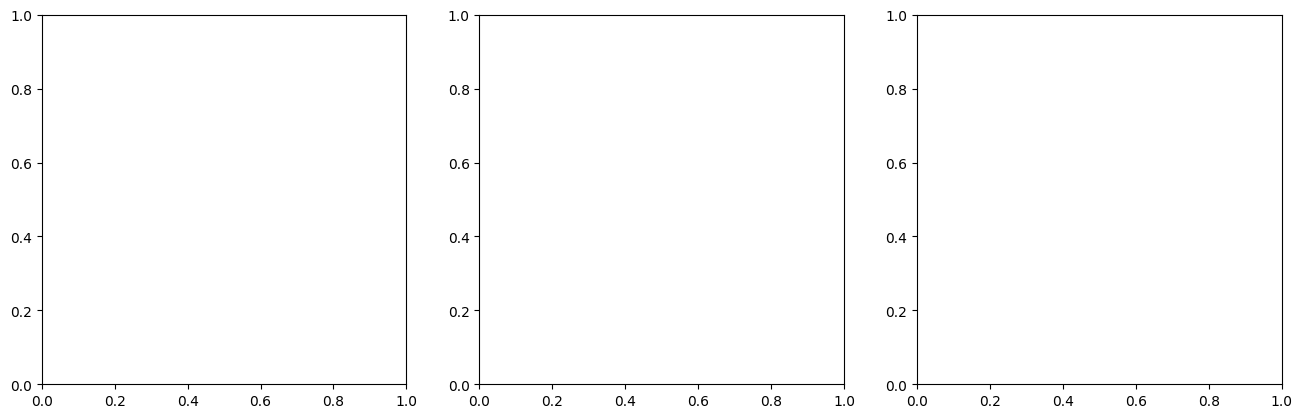

In [ ]:
import csv
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import ttest_rel

from datasets import get_MTL_Tasks
from networks.linear_network import MTL_linearnetwork
from utils import MTL_get_lambda_balanced_STLex


# --------------------------------------------------
# Sweep configuration
SEEDS = list(range(10))

SWEEP_TRAINING_STEPS = 60_000  # use 70_000 for the final sweep
LEARNING_RATE = 0.0002

IN_DIM = 5
HIDDEN_DIM = 2
OUT_DIM_1 = 1
OUT_DIM_2 = 1
BATCH_SIZE = 100

BETA = 0.4
EPS = 1e-8
WARMUP_STEPS = 20
CONFLICT_STRENGTH = 1.0

# theta = alignment factor
THETA_VALUES = np.linspace(0.0, 1.0, 5)

# log2(alpha_1 / alpha_2)
LOG_RATIO_VALUES = np.linspace(-2.0, 2.0, 5)

ALPHA_2 = 2.0


METHOD_CONFIGS = {
    "DWA": {
        "weighting_mode": "ema_relative",
        "gradient_surgery": "none",
    },
    "Conflict-DWA": {
        "weighting_mode": "conflict_ema",
        "gradient_surgery": "none",
    },
    "Conflict-PCGrad": {
        "weighting_mode": "none",
        "gradient_surgery": "pcgrad",
    },
}


# --------------------------------------------------
# One lightweight run for the AUC sweep
def run_sweep_case(
    alignment_factor,
    alpha_1,
    alpha_2,
    weighting_mode,
    gradient_surgery,
    seed,
    conflict_strength=1.0,
):
    # These resets ensure paired task instances and paired initializations.
    random.seed(seed)
    np.random.seed(seed)

    X, Y1, Y2 = get_MTL_Tasks(
        BATCH_SIZE,
        IN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        alpha_scales=(alpha_1, alpha_2),
        alignment_factor=alignment_factor,
        seed=seed,
    )

    init_ws, init_w1, init_w2 = MTL_get_lambda_balanced_STLex(
        0,
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        sigma_weights=0.0001,
    )

    model = MTL_linearnetwork(
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        init_ws=init_ws.copy(),
        init_w1=init_w1.copy(),
        init_w2=init_w2.copy(),
    )

    outputs = model.trainMTL(
        X.T,
        Y1,
        Y2,
        SWEEP_TRAINING_STEPS,
        LEARNING_RATE,
        trackgradients=False,
        save_weight_history=False,
        weighting_mode=weighting_mode,
        gradient_surgery=gradient_surgery,
        beta=BETA,
        eps=EPS,
        warmup_steps=WARMUP_STEPS,
        conflict_strength=conflict_strength,
    )

    _, _, _, losses1, losses2 = outputs

    losses1 = np.asarray(losses1, dtype=float)
    losses2 = np.asarray(losses2, dtype=float)

    combined_loss = 0.5 * (losses1 + losses2)

    # AUC is the average loss over the training trajectory.
    return float(np.mean(combined_loss))


# --------------------------------------------------
# Allocate paired AUC arrays
n_seeds = len(SEEDS)
n_theta = len(THETA_VALUES)
n_ratios = len(LOG_RATIO_VALUES)

auc_ew = np.zeros((n_seeds, n_theta, n_ratios), dtype=float)

auc_by_method = {
    method_name: np.zeros(
        (n_seeds, n_theta, n_ratios),
        dtype=float,
    )
    for method_name in METHOD_CONFIGS
}


# --------------------------------------------------
# Paired sweep
for theta_index, alignment_factor in enumerate(THETA_VALUES):
    for ratio_index, log_ratio in enumerate(LOG_RATIO_VALUES):
        alpha_1 = ALPHA_2 * 2.0 ** log_ratio

        for seed_index, seed in enumerate(SEEDS):
            # EW baseline
            auc_ew[seed_index, theta_index, ratio_index] = (
                run_sweep_case(
                    alignment_factor=alignment_factor,
                    alpha_1=alpha_1,
                    alpha_2=ALPHA_2,
                    weighting_mode="none",
                    gradient_surgery="none",
                    seed=seed,
                )
            )

            # Dynamic methods
            for method_name, config in METHOD_CONFIGS.items():
                auc_by_method[method_name][
                    seed_index,
                    theta_index,
                    ratio_index,
                ] = run_sweep_case(
                    alignment_factor=alignment_factor,
                    alpha_1=alpha_1,
                    alpha_2=ALPHA_2,
                    weighting_mode=config["weighting_mode"],
                    gradient_surgery=config["gradient_surgery"],
                    seed=seed,
                    conflict_strength=CONFLICT_STRENGTH,
                )

        print(
            f"completed theta={alignment_factor:.2f}, "
            f"log2 ratio={log_ratio:.2f}"
        )


# --------------------------------------------------
# Compute relative advantages and paired significance
relative_advantage = {}
p_values = {}
win_fraction = {}

for method_name in METHOD_CONFIGS:
    method_auc = auc_by_method[method_name]

    # Positive values mean the method has lower AUC than EW.
    paired_difference = auc_ew - method_auc

    relative_advantage[method_name] = (
        paired_difference
        / np.maximum(auc_ew, EPS)
    )

    # Paired t-test across seeds at each grid point.
    test_result = ttest_rel(
        auc_ew,
        method_auc,
        axis=0,
    )

    p_values[method_name] = test_result.pvalue

    win_fraction[method_name] = np.mean(
        paired_difference > 0.0,
        axis=0,
    )


# --------------------------------------------------
# Save numerical sweep results
output_prefix = Path("continuous_alignment_imbalance_sweep")

np.savez(
    f"{output_prefix}.npz",
    theta_values=THETA_VALUES,
    log_ratio_values=LOG_RATIO_VALUES,
    seeds=np.asarray(SEEDS),
    auc_ew=auc_ew,
    **{
        f"auc_{method_name}": method_auc
        for method_name, method_auc in auc_by_method.items()
    },
    **{
        f"advantage_{method_name}": values
        for method_name, values in relative_advantage.items()
    },
    **{
        f"pvalue_{method_name}": values
        for method_name, values in p_values.items()
    },
)

# Long-format CSV containing every paired AUC result.
with open(
    f"{output_prefix}.csv",
    "w",
    newline="",
) as csv_file:
    writer = csv.writer(csv_file)

    writer.writerow([
        "theta",
        "log2_alpha1_over_alpha2",
        "alpha1",
        "alpha2",
        "seed",
        "auc_ew",
        "method",
        "auc_method",
        "relative_advantage",
    ])

    for theta_index, alignment_factor in enumerate(THETA_VALUES):
        for ratio_index, log_ratio in enumerate(LOG_RATIO_VALUES):
            alpha_1 = ALPHA_2 * 2.0 ** log_ratio

            for seed_index, seed in enumerate(SEEDS):
                for method_name in METHOD_CONFIGS:
                    writer.writerow([
                        alignment_factor,
                        log_ratio,
                        alpha_1,
                        ALPHA_2,
                        seed,
                        auc_ew[
                            seed_index,
                            theta_index,
                            ratio_index,
                        ],
                        method_name,
                        auc_by_method[method_name][
                            seed_index,
                            theta_index,
                            ratio_index,
                        ],
                        relative_advantage[method_name][
                            theta_index,
                            ratio_index,
                        ],
                    ])

print(f"Saved: {output_prefix}.npz")
print(f"Saved: {output_prefix}.csv")


# --------------------------------------------------
# Plot one heatmap per method
all_advantages = np.concatenate([
    values.ravel()
    for values in relative_advantage.values()
])

maximum_abs_advantage = np.max(np.abs(all_advantages))

normalization = TwoSlopeNorm(
    vmin=-maximum_abs_advantage,
    vcenter=0.0,
    vmax=maximum_abs_advantage,
)

fig, axes = plt.subplots(
    1,
    len(METHOD_CONFIGS),
    figsize=(16, 4.8),
    squeeze=False,
)

axes = axes[0]

for axis, method_name in zip(axes, METHOD_CONFIGS):
    values = relative_advantage[method_name]

    image = axis.imshow(
        100.0 * values,
        origin="lower",
        aspect="auto",
        extent=[
            THETA_VALUES[0],
            THETA_VALUES[-1],
            LOG_RATIO_VALUES[0],
            LOG_RATIO_VALUES[-1],
        ],
        cmap="RdYlGn",
        norm=normalization,
    )

    # Mark statistically significant paired differences.
    significant = p_values[method_name] < 0.05

    for theta_index, alignment_factor in enumerate(THETA_VALUES):
        for ratio_index, log_ratio in enumerate(LOG_RATIO_VALUES):
            if significant[theta_index, ratio_index]:
                axis.scatter(
                    alignment_factor,
                    log_ratio,
                    marker="*",
                    color="black",
                    s=35,
                )

    axis.set_title(method_name)
    axis.set_xlabel(r"$\theta$ / alignment factor")
    axis.set_ylabel(r"$\log_2(\alpha_1/\alpha_2)$")

fig.colorbar(
    image,
    ax=axes,
    label="relative AUC advantage over EW (%)",
)

fig.suptitle(
    "Dynamic-method advantage over equal weighting",
    fontsize=15,
)

fig.tight_layout()
plt.show()

fig.savefig(
    f"{output_prefix}.png",
    dpi=220,
    bbox_inches="tight",
)

print(f"Saved: {output_prefix}.png")

In [ ]:
for axis, method_name in zip(axes, METHOD_CONFIGS):
    values = np.asarray(relative_advantage[method_name], dtype=float)

    # Average paired relative improvements over seeds.
    if values.ndim == 3:
        values = np.nanmean(values, axis=0)

    if values.shape != (len(LOG_RATIO_VALUES), len(THETA_VALUES)):
        raise ValueError(
            f"{method_name} has unexpected shape {values.shape}"
        )

    image = axis.imshow(
        100.0 * values,
        origin="lower",
        aspect="auto",
        extent=[
            THETA_VALUES[0],
            THETA_VALUES[-1],
            LOG_RATIO_VALUES[0],
            LOG_RATIO_VALUES[-1],
        ],
        cmap="RdYlGn",
        norm=normalization,
    )

    significant = p_values[method_name] < 0.05
    rows, columns = np.where(significant)

    axis.scatter(
        np.asarray(THETA_VALUES)[columns],
        np.asarray(LOG_RATIO_VALUES)[rows],
        marker="*",
        s=45,
        color="black",
        linewidths=0.5,
        label="paired $p<0.05$",
    )

    axis.set_title(method_name)
    axis.set_xlabel(r"alignment factor $\theta$")
    axis.set_ylabel(r"$\log_2(\alpha_1/\alpha_2)$")

NameError: name 'axes' is not defined

## Nonlinear Networks

In [ ]:
import importlib
import networks.relu_network as relu_network

importlib.reload(relu_network)
from networks.relu_network import MTLReLUNetwork
import random
import numpy as np

from datasets import get_MTL_Tasks
from networks.relu_network import MTLReLUNetwork
from utils import MTL_get_lambda_balanced_STLex


CONFLICT_STRENGTH = 1.0

SEEDS = list(range(5))

TRAINING_STEPS = 220_000
LEARNING_RATE = 0.0002

IN_DIM = 5
HIDDEN_DIM = 2
OUT_DIM_1 = 1
OUT_DIM_2 = 1
BATCH_SIZE = 100

ALIGNMENT_FACTOR = 0.5
ALPHA_1 = 1.0
ALPHA_2 = 1.0

BETA = 0.4
EPS = 1e-8
WARMUP_STEPS = 20


METHODS = {
    "EW": {
        "weighting_mode": "none",
        "gradient_surgery": "none",
    },
    "DWA": {
        "weighting_mode": "ema_relative",
        "gradient_surgery": "none",
    },
    "Conflict-DWA": {
        "weighting_mode": "conflict_ema",
        "gradient_surgery": "none",
        "conflict_strength": CONFLICT_STRENGTH,
    },
    "Conflict-PCGrad": {
        "weighting_mode": "none",
        "gradient_surgery": "pcgrad",
    },
}


def run_nonlinear_case(
    weighting_mode,
    seed,
    gradient_surgery="none",
    conflict_strength=1.0,
):
    random.seed(seed)
    np.random.seed(seed)

    X, Y1, Y2 = get_MTL_Tasks(
        BATCH_SIZE,
        IN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        alpha_scales=(ALPHA_1, ALPHA_2),
        alignment_factor=ALIGNMENT_FACTOR,
        seed=seed,
    )

    init_ws, init_w1, init_w2 = MTL_get_lambda_balanced_STLex(
        0,
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        sigma_weights=0.0001,
    )

    model = MTLReLUNetwork(
        IN_DIM,
        HIDDEN_DIM,
        OUT_DIM_1,
        OUT_DIM_2,
        init_ws=init_ws.copy(),
        init_w1=init_w1.copy(),
        init_w2=init_w2.copy(),
    )

    (
        wslist,
        w1list,
        w2list,
        losses1,
        losses2,
        cossim,
        gradmag1,
        gradmag2,
    ) = model.trainMTL(
        X.T,
        Y1,
        Y2,
        TRAINING_STEPS,
        LEARNING_RATE,
        trackgradients=True,
        save_weight_history=True,
        weighting_mode=weighting_mode,
        gradient_surgery=gradient_surgery,
        beta=BETA,
        eps=EPS,
        warmup_steps=WARMUP_STEPS,
        conflict_strength=conflict_strength,
    )

    losses1 = np.asarray(losses1, dtype=float)
    losses2 = np.asarray(losses2, dtype=float)

    return {
        "losses1": losses1,
        "losses2": losses2,
        "combined_loss": 0.5 * (losses1 + losses2),
        "w1": np.asarray(model.taskweight1_history, dtype=float),
        "w2": np.asarray(model.taskweight2_history, dtype=float),
        "cossim": np.asarray(cossim, dtype=float),
        "postsurg_cossim": np.asarray(
            model.postsurg_cossim_history,
            dtype=float,
        ),
        "gradmag1": np.asarray(gradmag1, dtype=float),
        "gradmag2": np.asarray(gradmag2, dtype=float),
        "conflict_score": np.asarray(
            model.conflict_score_history,
            dtype=float,
        ),
        "wslist": wslist,
        "w1list": w1list,
        "w2list": w2list,
    }


results = {
    method_name: []
    for method_name in METHODS
}

for method_name, config in METHODS.items():
    for seed in SEEDS:
        print(f"Running {method_name}, seed={seed}")

        results[method_name].append(
            run_nonlinear_case(
                weighting_mode=config["weighting_mode"],
                gradient_surgery=config["gradient_surgery"],
                conflict_strength=config.get(
                    "conflict_strength",
                    1.0,
                ),
                seed=seed,
            )
        )

print("Finished nonlinear ReLU experiment.")

Running EW, seed=0
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
Running EW, seed=1
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
Running EW, seed=2
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
Running EW, seed=3
diffinitfunv [[-1.69406589e-20 -1.35525272e-20]
 [-1.35525272e-20  0.00000000e+00]]
Running EW, seed=4
diffinitfunv [[ 7.83505476e-21 -5.08219768e-21]
 [-5.08219768e-21  2.71050543e-20]]
Running DWA, seed=0
diffinitfunv [[-1.08420217e-19  5.75982404e-20]
 [ 5.75982404e-20 -3.30342849e-20]]
Running DWA, seed=1
diffinitfunv [[ 2.71050543e-20 -2.71050543e-20]
 [-2.71050543e-20  2.71050543e-20]]
Running DWA, seed=2
diffinitfunv [[ 2.92226367e-20 -7.11507676e-20]
 [-7.11507676e-20 -6.77626358e-20]]
Running DWA, seed=3
diffinitfunv [[-1.69406589e-20 -1.35525272e-20]
 [-1.35525272e-20  0.00000000e+00]]
Running DWA, seed=4
diffinitfunv [[ 7.83505476e-21 -5.08219768e-21]
 

## TASK GROUPING

In [85]:

# ============================================================
# Task-generation and spectral-alignment setup
# ============================================================

IN = 16
OUT = 8
HID=16
N_PAIRS = 20
N_EST = 10_000
NOISE_STD = 0.0
TAG_START = 500
TAG_END = 2000
TAG_STRIDE = 1
TAG_RELATIVE_FLOOR = 1e-8
LR=0.0001
INIT=0.001
assert 2 * OUT <= IN


def random_task_pair(
    rng,
    gamma,
    log_ratio=0.0,
    s2=2.0,
):
    """
    Generate two linear task maps.

    gamma:
        Task-generation alignment parameter in [0, 1].

    log_ratio:
        Log2 scale ratio between task 1 and task 2.
    """

    Q_full, _ = np.linalg.qr(
        rng.standard_normal((IN, IN))
    )

    # Task 1 occupies the first OUT-dimensional subspace
    W1 = Q_full[:, :OUT].T

    # Orthogonal subspace for task 2
    W_orthogonal = Q_full[:, OUT:2 * OUT].T

    # Interpolate between aligned and orthogonal task subspaces
    W2 = (
        gamma * W1
        + (1.0 - gamma) * W_orthogonal
    )

    # Equalize Frobenius norms
    W2 = (
        W2
        / np.linalg.norm(W2, ord="fro")
        * np.linalg.norm(W1, ord="fro")
    )

    W1 = (
        W1
        / np.linalg.norm(W1, ord="fro")
        * np.linalg.norm(W2, ord="fro")
    )

    # Task-scale imbalance
    scale_1 = s2 * 2.0 ** log_ratio
    scale_2 = s2

    A1 = scale_1 * W1
    A2 = scale_2 * W2

    return A1, A2


def estimate_spectral_alignment(
    rng,
    A1,
    A2,
    n_est=N_EST,
    noise_std=NOISE_STD,
):
    """
    Estimate the spectral alignment defined by

        O_12 = V_1^T V_2,

    where V_i contains the right singular vectors of
    the task map A_i.
    """

    X = rng.standard_normal((n_est, IN))

    Y1 = (
        A1 @ X.T
        + noise_std
        * rng.standard_normal((OUT, n_est))
    )

    Y2 = (
        A2 @ X.T
        + noise_std
        * rng.standard_normal((OUT, n_est))
    )

    # Empirical task maps
    Sigma1_hat = (Y1 @ X) / n_est
    Sigma2_hat = (Y2 @ X) / n_est

    # Right singular vectors
    _, S1, Vt1 = np.linalg.svd(
        Sigma1_hat,
        full_matrices=False,
    )

    _, S2, Vt2 = np.linalg.svd(
        Sigma2_hat,
        full_matrices=False,
    )

    tol1 = (
        max(Sigma1_hat.shape)
        * np.max(S1)
        * 1e-10
    )

    tol2 = (
        max(Sigma2_hat.shape)
        * np.max(S2)
        * 1e-10
    )

    rank1 = np.sum(S1 > tol1)
    rank2 = np.sum(S2 > tol2)

    V1_hat = Vt1[:rank1].T
    V2_hat = Vt2[:rank2].T

    # Overlap matrix
    O12_hat = V1_hat.T @ V2_hat

    # Singular values of the overlap matrix
    alpha_hat = np.linalg.svd(
        O12_hat,
        compute_uv=False,
    )

    # Scalar summary
    alpha_mean_hat = np.mean(alpha_hat)

    return (
        alpha_mean_hat,
        alpha_hat,
        O12_hat,
    )



def run(
    A1,
    A2,
    active,
    steps,
    seed,
    lr=LR,
    tag_start=TAG_START,
    tag_end=TAG_END,
    tag_stride=TAG_STRIDE,
    hid=HID,
):
    rng = np.random.default_rng(seed)

    # Network parameters
    Ws = INIT * rng.standard_normal((hid, IN))
    W1 = INIT * rng.standard_normal((OUT, hid))
    W2 = INIT * rng.standard_normal((OUT, hid))

    losses1 = np.empty(steps, dtype=float)
    losses2 = np.empty(steps, dtype=float)

    tag_terms = {
    name: []
    for name in TAG_WINDOWS
    }

    for t in range(steps):

        # Current task errors
        E1 = W1 @ Ws - A1
        E2 = W2 @ Ws - A2

        # Current losses
        L1 = 0.5 * np.sum(E1 ** 2)
        L2 = 0.5 * np.sum(E2 ** 2)

        losses1[t] = L1
        losses2[t] = L2

        # Gradients with respect to shared parameters
        g1 = (
            W1.T @ E1
            if 1 in active
            else np.zeros_like(Ws)
        )

        g2 = (
            W2.T @ E2
            if 2 in active
            else np.zeros_like(Ws)
        )

        # --------------------------------------------------------
        # TAG measurement
        # --------------------------------------------------------
        if (1 in active
            and 2 in active
            and (t % tag_stride == 0)
        ):
            min_L1 = (
            TAG_RELATIVE_FLOOR
            * max(abs(L1), 1.0)
            )

            min_L2 = (
            TAG_RELATIVE_FLOOR
            * max(abs(L2), 1.0)
            )

            if L1 > min_L1 and L2 > min_L2:

                Ws_from1 = Ws - lr * g1
                Ws_from2 = Ws - lr * g2

                L2_after_from1 = 0.5 * np.sum(
                    (W2 @ Ws_from1 - A2) ** 2
                    )

                L1_after_from2 = 0.5 * np.sum(
                    (W1 @ Ws_from2 - A1) ** 2
                    )

                Z_1_to_2 = (
                    1.0 - L2_after_from1 / L2
                    )

                Z_2_to_1 = (
                    1.0 - L1_after_from2 / L1
                )

        # Store the same TAG observation in
        # whichever windows contain this step.
                for name, (start, end) in TAG_WINDOWS.items():
                    if start <= t < end:
                        tag_terms[name].append(
                            (Z_1_to_2, Z_2_to_1)
                        )
                '''
                Z_1_to_2_linear = (
                lr * np.sum(g1 * g2) / L2
                )

                Z_2_to_1_linear = (
                lr * np.sum(g1 * g2) / L1
                )
                if t == tag_start:
                    print(
                    "Exact Z_1_to_2:",
                    Z_1_to_2,
                    "Linear approximation:",
                    Z_1_to_2_linear,
                    )

                    print(
                    "Exact Z_2_to_1:",
                    Z_2_to_1,
                    "Linear approximation:",
                    Z_2_to_1_linear,
                    )
                '''
        # --------------------------------------------------------
        # Actual simultaneous gradient update
        # --------------------------------------------------------
        Ws_old = Ws.copy()

        Ws = Ws_old - lr * (g1 + g2)

        if 1 in active:
            W1 = W1 - lr * (E1 @ Ws_old.T)

        if 2 in active:
            W2 = W2 - lr * (E2 @ Ws_old.T)

    # ------------------------------------------------------------
    # Training-level symmetric TAG affinity
    # ------------------------------------------------------------
    tag_affinity = {}

    for name, terms in tag_terms.items():

        if len(terms) > 0:
            terms = np.asarray(
            terms,
            dtype=float,
            )

            tag_affinity[name] = 0.5 * (
                np.mean(terms[:, 0])
            + np.mean(terms[:, 1])
            )
        else:
            tag_affinity[name] = np.nan

    return losses1, losses2, tag_affinity
# ============================================================
# Generate task pairs and estimate their alignment
# ============================================================



In [88]:
def compute_nti_metrics(
    losses1_joint,
    losses2_joint,
    losses1_iso,
    losses2_iso,
    early_start=0,
    early_end=3500,
    late_start=None,
    late_end=None,
    final_window=500,
):
    joint = losses1_joint + losses2_joint
    isolated = losses1_iso + losses2_iso
    difference = joint - isolated

    if late_start is None:
        late_start = max(
            0,
            len(difference) - 3500,
        )

    if late_end is None:
        late_end = len(difference)

    return {
        "nti_full": np.mean(difference),

        "nti_early": np.mean(
            difference[early_start:early_end]
        ),

        "nti_late": np.mean(
            difference[late_start:late_end]
        ),

        "nti_final": np.mean(
            difference[-final_window:]
        ),
    }

In [105]:
task_rng = np.random.default_rng(42)

task_pairs = []
N_PAIRS=(70)

for pair_id in range(N_PAIRS):

    gamma = task_rng.uniform(0.0, 1.0)

    # Keep task scales equal
    log_ratio = 0.0

    A1, A2 = random_task_pair(
        rng=task_rng,
        gamma=gamma,
        log_ratio=log_ratio,
    )

    alignment_rng = np.random.default_rng(
        100000 + pair_id
    )

    (
        alpha_mean_hat,
        alpha_hat,
        O12_hat,
    ) = estimate_spectral_alignment(
        rng=alignment_rng,
        A1=A1,
        A2=A2,
    )

    task_pairs.append(
        {
            "pair_id": pair_id,
            "gamma": gamma,
            "log_ratio": log_ratio,
            "alpha_hat": alpha_mean_hat,
            "alpha_spectrum": alpha_hat,
            "O12_hat": O12_hat,
            "A1": A1,
            "A2": A2,
        }
    )

print(f"Generated {len(task_pairs)} task pairs.")

print(
    "Example pair:",
    {
        "gamma": task_pairs[0]["gamma"],
        "alpha_hat": task_pairs[0]["alpha_hat"],
        "alpha_spectrum": task_pairs[0]["alpha_spectrum"],
    },
)


# ============================================================
# Population sweep
# ============================================================

SEEDS = np.arange(10)       # use np.arange(1) only for debugging


HID_ISOLATED = HID          # same architecture for fair TAG comparison
STEPS=60000
TAG_START = 9
TAG_END = STEPS
TAG_STRIDE = 1

records = []
loss_history = None
INSPECT_PAIR_ID = 0
INSPECT_SEED = 0
STEPS = 60_000
WINDOW_LENGTH = 3500

TAG_WINDOWS = {
    "full": (
        0,
        STEPS,
    ),
    "early": (
        0,
        min(WINDOW_LENGTH, STEPS),
    ),
    "late": (
        max(0, STEPS - WINDOW_LENGTH),
        STEPS,
    ),
}
inspection_history = None
for pair in task_pairs:

    pair_id = pair["pair_id"]
    gamma = pair["gamma"]
    log_ratio = pair["log_ratio"]
    A1 = pair["A1"]
    A2 = pair["A2"]

    for seed in SEEDS:

        run_seed = 100000 + 1000 * pair_id + int(seed)

        # STL task 1
        losses1_iso, _, _ = run(
            A1,
            A2,
            active={1},
            steps=STEPS,
            seed=run_seed,
            hid=HID_ISOLATED,
        )

        # STL task 2
        _, losses2_iso, _ = run(
            A1,
            A2,
            active={2},
            steps=STEPS,
            seed=run_seed,
            hid=HID_ISOLATED,
        )

        # Joint MTL
        losses1_joint, losses2_joint, tag_affinity = run(
        A1,
        A2,
        active={1, 2},
        steps=STEPS,
        seed=run_seed,
        tag_stride=1,
        hid=HID,
        )

        if pair_id == 0 and seed == 0:
            loss_history = {
                "task1_isolated": losses1_iso.copy(),
                "task2_isolated": losses2_iso.copy(),
                "task1_joint": losses1_joint.copy(),
                "task2_joint": losses2_joint.copy(),
                "gamma": gamma,
                "log_ratio": log_ratio,
            }

        # IMPORTANT: exactly the same window as TAG
        nti_metrics = compute_nti_metrics(
          losses1_joint,
          losses2_joint,
          losses1_iso,
          losses2_iso,
          early_start=0,
          early_end=3500,
          late_start=STEPS - 3500,
          late_end=STEPS,
          final_window=500,
           )
        if (pair_id == INSPECT_PAIR_ID
        and int(seed) == INSPECT_SEED
        ):
            inspection_history = {
        "pair_id": pair_id,
        "seed": int(seed),
        "run_seed": run_seed,

        # Task-generation and measured alignment
        "gamma": gamma,
        "rho": pair["alpha_hat"],
        "alpha_spectrum": pair["alpha_spectrum"],

        # TAG and NTI values
        "tag_aff": tag_aff,
        "nti_full": nti_metrics["nti_full"],
        "nti_early": nti_metrics["nti_early"],
        "nti_final": nti_metrics["nti_final"],

        # Complete loss curves
        "task1_isolated": losses1_iso.copy(),
        "task2_isolated": losses2_iso.copy(),
        "task1_joint": losses1_joint.copy(),
        "task2_joint": losses2_joint.copy(),
    }
        records.append(
        {
        "pair_id": pair_id,
        "seed": int(seed),
        "gamma": gamma,
        "alpha_hat": pair["alpha_hat"],

        "tag_full": tag_affinity["full"],
        "tag_early": tag_affinity["early"],
        "tag_late": tag_affinity["late"],

        "nti_full": nti_metrics["nti_full"],
        "nti_early": nti_metrics["nti_early"],
        "nti_late": nti_metrics["nti_late"],
        "nti_fnal": nti_metrics["nti_final"],
        }
        )

print("Completed records:", len(records))
print("Expected records:", N_PAIRS * len(SEEDS))

Generated 70 task pairs.
Example pair: {'gamma': 0.7739560485559633, 'alpha_hat': np.float64(0.9601241386436663), 'alpha_spectrum': array([0.96500925, 0.96372244, 0.96273367, 0.96091945, 0.96048845,
       0.95908351, 0.95538948, 0.95364685])}
Completed records: 700
Expected records: 700


In [106]:
from pathlib import Path
import pickle
import pandas as pd

save_dir = Path.cwd()

# Full checkpoint: preserves NumPy arrays and task maps
checkpoint_path = save_dir / "mtl_tag_checkpoint.pkl"

checkpoint = {
    "records": records,
    "task_pairs": task_pairs,
    "loss_history": loss_history,
    "inspection_history": inspection_history,
    "config": {
        "N_PAIRS": N_PAIRS,
        "SEEDS": np.asarray(SEEDS),
        "STEPS": STEPS,
        "HID": HID,
        "HID_ISOLATED": HID_ISOLATED,
        "TAG_WINDOWS": TAG_WINDOWS,
    },
}

with open(checkpoint_path, "wb") as f:
    pickle.dump(checkpoint, f)

# Human-readable table
csv_path = save_dir / "mtl_tag_records.csv"
pd.DataFrame(records).to_csv(
    csv_path,
    index=False,
)

print("Saved full checkpoint to:", checkpoint_path)
print("Saved records table to:", csv_path)
print("Number of records:", len(records))

Saved full checkpoint to: c:\Users\emgregoi\Desktop\Research Projects\InterTaskDynamics\ICML26\Figure3_dynamicscodeclem\ExactLearningDynamicsRichLazy-main\mtl_tag_checkpoint.pkl
Saved records table to: c:\Users\emgregoi\Desktop\Research Projects\InterTaskDynamics\ICML26\Figure3_dynamicscodeclem\ExactLearningDynamicsRichLazy-main\mtl_tag_records.csv
Number of records: 700


In [107]:
pair_ids = sorted(
    set(r["pair_id"] for r in records)
)

print("Pairs:", len(pair_ids))
print("Records:", len(records))


rho_plot = np.asarray([
    next(
        r["alpha_hat"]
        for r in records
        if r["pair_id"] == pair_id
    )
    for pair_id in pair_ids
])


def summarize_field(field):
    means = []
    stds = []

    for pair_id in pair_ids:
        values = np.asarray([
            r[field]
            for r in records
            if r["pair_id"] == pair_id
        ], dtype=float)

        means.append(np.nanmean(values))

        stds.append(
            np.nanstd(
                values,
                ddof=1 if len(values) > 1 else 0,
            )
        )

    return (
        np.asarray(means),
        np.asarray(stds),
    )

Pairs: 70
Records: 700


In [108]:
tag_full, tag_full_std = summarize_field(
    "tag_full"
)

tag_early, tag_early_std = summarize_field(
    "tag_early"
)

tag_late, tag_late_std = summarize_field(
    "tag_late"
)

nti_full, nti_full_std = summarize_field(
    "nti_full"
)

nti_early, nti_early_std = summarize_field(
    "nti_early"
)

nti_late, nti_late_std = summarize_field(
    "nti_late"
)

nti_final, nti_final_std = summarize_field(
    "nti_fnal"
)

In [109]:
report_correlation(
    "Alignment vs full NTI",
    rho_plot,
    nti_full,
)

report_correlation(
    "TAG full vs full NTI",
    tag_full,
    nti_full,
)


report_correlation(
    "Alignment vs early NTI",
    rho_plot,
    nti_early,
)

report_correlation(
    "TAG early vs early NTI",
    tag_early,
    nti_early,
)


report_correlation(
    "Alignment vs late NTI",
    rho_plot,
    nti_late,
)

report_correlation(
    "TAG late vs late NTI",
    tag_late,
    nti_late,
)


Alignment vs full NTI
Number of pairs: 70
Pearson: PearsonRResult(statistic=np.float64(-0.9508971055080171), pvalue=np.float64(2.3491466220675736e-36))
Spearman: SignificanceResult(statistic=np.float64(-0.9963257807715861), pvalue=np.float64(2.5652053959380877e-74))

TAG full vs full NTI
Number of pairs: 70
Pearson: PearsonRResult(statistic=np.float64(0.549335411735115), pvalue=np.float64(8.450048307696317e-07))
Spearman: SignificanceResult(statistic=np.float64(0.5286151692765287), pvalue=np.float64(2.553202808575119e-06))

Alignment vs early NTI
Number of pairs: 70
Pearson: PearsonRResult(statistic=np.float64(-0.9550754918869793), pvalue=np.float64(1.2230640198264544e-37))
Spearman: SignificanceResult(statistic=np.float64(-0.9594436182311258), pvalue=np.float64(4.055670253551169e-39))

TAG early vs early NTI
Number of pairs: 70
Pearson: PearsonRResult(statistic=np.float64(-0.9992841760235845), pvalue=np.float64(1.894686040391751e-98))
Spearman: SignificanceResult(statistic=np.float64

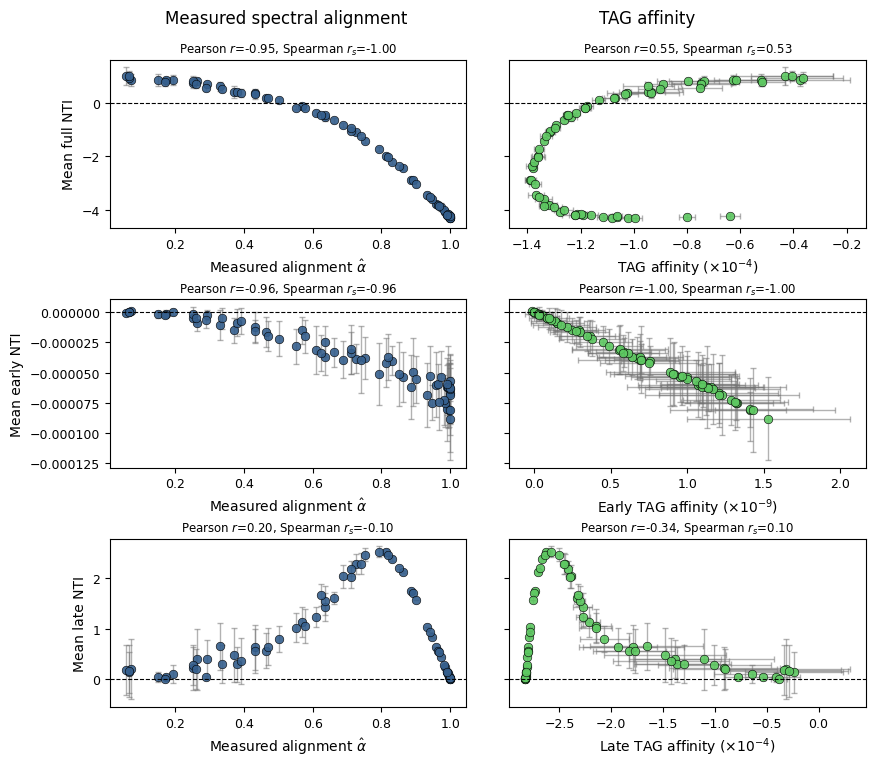

In [120]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


def corr_label(x, y):
    valid = np.isfinite(x) & np.isfinite(y)

    pearson = stats.pearsonr(
        x[valid],
        y[valid],
    ).statistic

    spearman = stats.spearmanr(
        x[valid],
        y[valid],
    ).statistic

    return (
        f"Pearson $r$={pearson:.2f}, "
        f"Spearman $r_s$={spearman:.2f}"
    )

# Plot-only scaling factors
FULL_TAG_SCALE = 1e4
EARLY_TAG_SCALE = 1e9
LATE_TAG_SCALE = 1e4
# Expected arrays:
# rho_plot
# tag_full, tag_full_std
# tag_early, tag_early_std
# tag_late, tag_late_std
# nti_full, nti_full_std
# nti_early, nti_early_std
# nti_late, nti_late_std


rho_color = plt.cm.viridis(0.30)
tag_color = plt.cm.viridis(0.75)

fig, axes = plt.subplots(
    3,
    2,
    figsize=(8.4, 7.8),
    sharey="row",
)


def draw_panel(
    ax,
    x,
    y,
    yerr,
    color,
    xlabel,
    subtitle,
    xerr=None,
):
    ax.errorbar(
        x,
        y,
        xerr=xerr,
        yerr=yerr,
        fmt="none",
        ecolor="0.45",
        elinewidth=1,
        capsize=2,
        alpha=0.55,
        zorder=1,
    )

    ax.scatter(
        x,
        y,
        s=38,
        color=color,
        edgecolor="black",
        linewidth=0.45,
        alpha=0.9,
        zorder=2,
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8,
    )

    ax.text(
        0.5,
        1.015,
        subtitle,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

    ax.set_xlabel(xlabel)
    ax.grid(False)
    ax.tick_params(labelsize=9)


# ============================================================
# Full trajectory
# ============================================================

draw_panel(
    axes[0, 0],
    rho_plot,
    nti_full,
    nti_full_std,
    rho_color,
    r"Measured alignment $\hat{\alpha}$",
    corr_label(rho_plot, nti_full),
)

draw_panel(
    axes[0, 1],
    FULL_TAG_SCALE * tag_full,
    nti_full,
    nti_full_std,
    tag_color,
    r"TAG affinity ($\times 10^{-4}$)",
    corr_label(tag_full, nti_full),
    xerr=FULL_TAG_SCALE * tag_full_std,
)

# ============================================================
# Early training
# ============================================================

draw_panel(
    axes[1, 0],
    rho_plot,
    nti_early,
    nti_early_std,
    rho_color,
    r"Measured alignment $\hat{\alpha}$",
    corr_label(rho_plot, nti_early),
)

draw_panel(
    axes[1, 1],
    EARLY_TAG_SCALE * tag_early,
    nti_early,
    nti_early_std,
    tag_color,
    r"Early TAG affinity ($\times 10^{-9}$)",
    corr_label(tag_early, nti_early),
    xerr=EARLY_TAG_SCALE * tag_early_std,
)

# ============================================================
# Late training
# ============================================================

draw_panel(
    axes[2, 0],
    rho_plot,
    nti_late,
    nti_late_std,
    rho_color,
    r"Measured alignment $\hat{\alpha}$",
    corr_label(rho_plot, nti_late),
)

draw_panel(
    axes[2, 1],
    LATE_TAG_SCALE * tag_late,
    nti_late,
    nti_late_std,
    tag_color,
    r"Late TAG affinity ($\times 10^{-4}$)",
    corr_label(tag_late, nti_late),
    xerr=LATE_TAG_SCALE * tag_late_std,
)


# Column headers
fig.text(
    0.29,
    0.975,
    "Measured spectral alignment",
    ha="center",
    va="top",
    fontsize=12,
)

fig.text(
    0.72,
    0.975,
    "TAG affinity",
    ha="center",
    va="top",
    fontsize=12,
)


axes[0, 0].set_ylabel("Mean full NTI")
axes[1, 0].set_ylabel("Mean early NTI")
axes[2, 0].set_ylabel("Mean late NTI")

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.91,
    wspace=0.12,
    hspace=0.42,
)

plt.show()


In [115]:
print(records[0].keys())

dict_keys(['pair_id', 'seed', 'gamma', 'alpha_hat', 'tag_full', 'tag_early', 'tag_late', 'nti_full', 'nti_early', 'nti_late', 'nti_fnal'])


In [116]:
import pandas as pd
from scipy import stats

tag_windows = {
    "TAG full": tag_full,
    "TAG early": tag_early,
    "TAG late": tag_late,
}

nti_windows = {
    "NTI full": nti_full,
    "NTI early": nti_early,
    "NTI late": nti_late,
}

rows = []

for tag_name, tag_values in tag_windows.items():
    for nti_name, nti_values in nti_windows.items():

        valid = (
            np.isfinite(tag_values)
            & np.isfinite(nti_values)
        )

        pearson = stats.pearsonr(
            tag_values[valid],
            nti_values[valid],
        ).statistic

        spearman = stats.spearmanr(
            tag_values[valid],
            nti_values[valid],
        ).statistic

        rows.append(
            {
                "TAG window": tag_name,
                "NTI window": nti_name,
                "Pearson": pearson,
                "Spearman": spearman,
            }
        )

correlation_table = pd.DataFrame(rows)

display(
    correlation_table.round(3)
)

,TAG window,NTI window,Pearson,Spearman
0,TAG full,NTI full,0.549,0.529
1,TAG full,NTI early,0.633,0.591
2,TAG full,NTI late,-0.640,-0.732
3,TAG early,NTI full,-0.970,-0.968
4,TAG early,NTI early,-0.999,-0.999
5,TAG early,NTI late,0.063,-0.044
6,TAG late,NTI full,0.855,0.994
7,TAG late,NTI early,0.890,0.960
8,TAG late,NTI late,-0.340,0.099


ValueError: 'x' and 'y' must have the same size

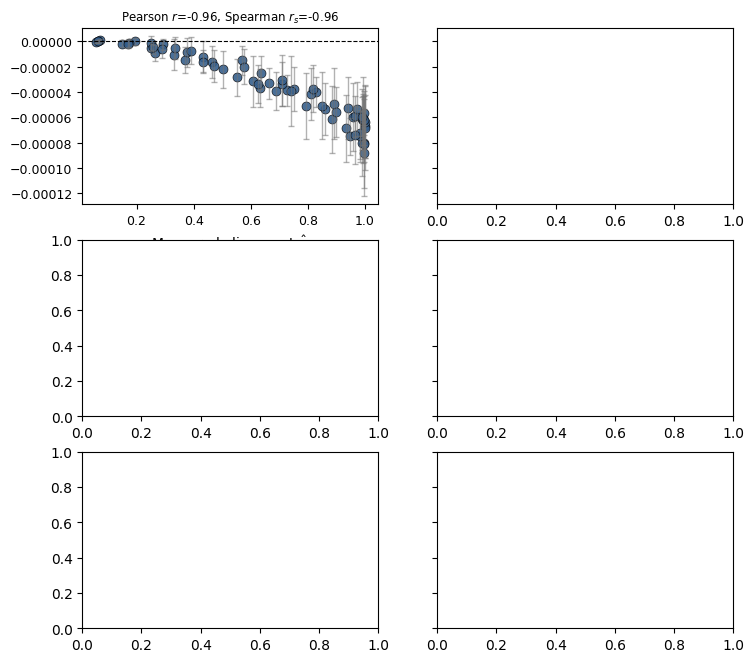

In [110]:
fig, axes = plt.subplots(
    3,
    2,
    figsize=(8.4, 7.8),
    sharey="row",
)

rho_color = plt.cm.viridis(0.30)
tag_color = plt.cm.viridis(0.75)


def draw_panel(
    ax,
    x,
    y,
    yerr,
    color,
    xlabel,
    corr_x,
    corr_y,
    xerr=None,
):
    ax.errorbar(
        x,
        y,
        xerr=xerr,
        yerr=yerr,
        fmt="none",
        ecolor="0.45",
        elinewidth=1,
        capsize=2,
        alpha=0.55,
    )

    ax.scatter(
        x,
        y,
        s=42,
        color=color,
        edgecolor="black",
        linewidth=0.45,
        alpha=0.9,
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8,
    )

    # Pearson/Spearman subtitle
    ax.text(
        0.5,
        1.015,
        corr_label(corr_x, corr_y),
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

    ax.set_xlabel(xlabel)
    ax.grid(False)
    ax.tick_params(labelsize=9)


# ------------------------------------------------------------
# Early NTI
# ------------------------------------------------------------

draw_panel(
    axes[0, 0],
    rho_plot,
    nti_early,
    nti_early_std,
    rho_color,
    r"Measured alignment $\hat{\rho}$",
    rho_plot,
    nti_early,
)

draw_panel(
    axes[0, 1],
    tag_plot,
    nti_early,
    nti_early_std,
    tag_color,
    "TAG affinity",
    tag_plot,
    nti_early,
    xerr=tag_std,
)


# ------------------------------------------------------------
# Final NTI
# ------------------------------------------------------------

draw_panel(
    axes[1, 0],
    rho_plot,
    nti_final,
    nti_final_std,
    rho_color,
    r"Measured alignment $\hat{\rho}$",
    rho_plot,
    nti_final,
)

draw_panel(
    axes[1, 1],
    tag_plot,
    nti_final,
    nti_final_std,
    tag_color,
    "TAG affinity",
    tag_plot,
    nti_final,
    xerr=tag_std,
)


# ------------------------------------------------------------
# Full NTI
# ------------------------------------------------------------

draw_panel(
    axes[2, 0],
    rho_plot,
    nti_full_mean,
    nti_full_std,
    rho_color,
    r"Measured alignment $\hat{\rho}$",
    rho_plot,
    nti_full_mean,
)

draw_panel(
    axes[2, 1],
    tag_plot,
    nti_full_mean,
    nti_full_std,
    tag_color,
    "TAG affinity",
    tag_plot,
    nti_full_mean,
    xerr=tag_std,
)


# Column titles: only once
fig.text(
    0.29,
    0.975,
    "Measured spectral alignment",
    ha="center",
    va="top",
    fontsize=12,
)

fig.text(
    0.72,
    0.975,
    "TAG affinity",
    ha="center",
    va="top",
    fontsize=12,
)


axes[0, 0].set_ylabel("Mean early NTI")
axes[1, 0].set_ylabel("Mean final NTI")
axes[2, 0].set_ylabel("Mean full NTI")

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.91,
    wspace=0.12,
    hspace=0.42,
)

plt.show()

In [102]:
report_correlation(
    "Alignment vs early NTI",
    rho_plot,
    nti_early,
)

report_correlation(
    "TAG early vs early NTI",
    tag_early,
    nti_early,
)


report_correlation(
    "Alignment vs late NTI",
    rho_plot,
    nti_late,
)

report_correlation(
    "TAG late vs late NTI",
    tag_late,
    nti_late,
)


report_correlation(
    "Alignment vs full NTI",
    rho_plot,
    nti_full,
)

report_correlation(
    "TAG full vs full NTI",
    tag_full,
    nti_full,
)


Alignment vs early NTI
Number of pairs: 5
Pearson: PearsonRResult(statistic=np.float64(-0.853007327479958), pvalue=np.float64(0.06613969373554601))
Spearman: SignificanceResult(statistic=np.float64(-0.7), pvalue=np.float64(0.1881204043741873))

TAG early vs early NTI
Number of pairs: 5
Pearson: PearsonRResult(statistic=np.float64(-0.9953108778428014), pvalue=np.float64(0.00038518154693539493))
Spearman: SignificanceResult(statistic=np.float64(-0.9999999999999999), pvalue=np.float64(1.4042654220543672e-24))

Alignment vs late NTI
Number of pairs: 5
Pearson: PearsonRResult(statistic=np.float64(0.6760447388863048), pvalue=np.float64(0.21025259494133458))
Spearman: SignificanceResult(statistic=np.float64(0.7), pvalue=np.float64(0.1881204043741873))

TAG late vs late NTI
Number of pairs: 5
Pearson: PearsonRResult(statistic=np.float64(-0.7669514544705441), pvalue=np.float64(0.1302287068298029))
Spearman: SignificanceResult(statistic=np.float64(-0.7), pvalue=np.float64(0.1881204043741873))



In [59]:
rho_true = []
rho_estimated = []

for pair in task_pairs:
    gamma = pair["gamma"]

    rho_true.append(
        gamma
        / np.sqrt(
            gamma**2 + (1.0 - gamma)**2
        )
    )

    rho_estimated.append(pair["alpha_hat"])

rho_true = np.asarray(rho_true)
rho_estimated = np.asarray(rho_estimated)

print(
    "Maximum alignment estimation error:",
    np.max(np.abs(rho_true - rho_estimated)),
)

print(
    "Alignment correlation:",
    stats.pearsonr(
        rho_true,
        rho_estimated,
    ),
)

Maximum alignment estimation error: 0.010447535105701622
Alignment correlation: PearsonRResult(statistic=np.float64(0.9999215579848603), pvalue=np.float64(8.339727498601106e-07))


In [60]:
def residualize(y, x):
    coefficients = np.polyfit(x, y, deg=1)
    prediction = np.polyval(coefficients, x)
    return y - prediction


tag_residual = residualize(
    tag_mean,
    rho,
)

nti_residual = residualize(
    nti_final,
    rho,
)

print(
    "Partial TAG–final NTI correlation:",
    stats.pearsonr(
        tag_residual,
        nti_residual,
    ),
)

TypeError: expected x and y to have same length

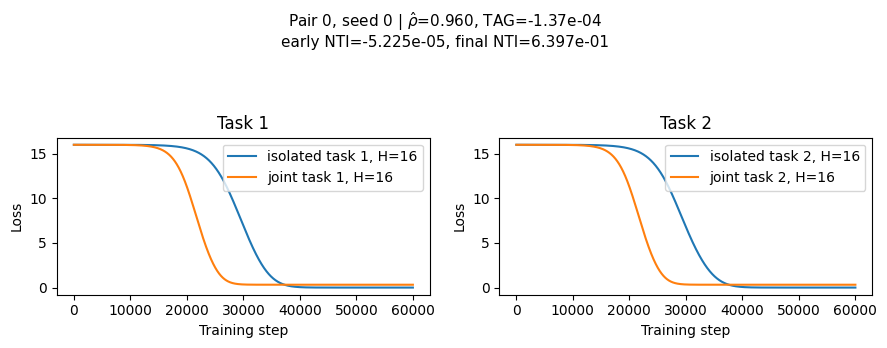

In [111]:
h = inspection_history

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9, 3.5),
)

# Task 1
axes[0].plot(
    h["task1_isolated"],
    label=f"isolated task 1, H={HID_ISOLATED}",
    color="tab:blue",
)

axes[0].plot(
    h["task1_joint"],
    label=f"joint task 1, H={HID}",
    color="tab:orange",
)

axes[0].set(
    xlabel="Training step",
    ylabel="Loss",
    title="Task 1",
)

axes[0].legend()
axes[0].grid(False)


# Task 2
axes[1].plot(
    h["task2_isolated"],
    label=f"isolated task 2, H={HID_ISOLATED}",
    color="tab:blue",
)

axes[1].plot(
    h["task2_joint"],
    label=f"joint task 2, H={HID}",
    color="tab:orange",
)

axes[1].set(
    xlabel="Training step",
    ylabel="Loss",
    title="Task 2",
)

axes[1].legend()
axes[1].grid(False)


fig.suptitle(
    f"Pair {h['pair_id']}, seed {h['seed']} | "
    f"$\\hat{{\\rho}}$={h['rho']:.3f}, "
    f"TAG={h['tag_aff']:.2e}\n"
    f"early NTI={h['nti_early']:.3e}, "
    f"final NTI={h['nti_final']:.3e}",
    fontsize=11,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.88]
)

plt.show()

In [82]:
pair_ids = sorted(
    set(r["pair_id"] for r in records)
)

print("Current pair IDs:", pair_ids)
print("Current records:", len(records))
print("Expected records:", N_PAIRS * len(SEEDS))

assert len(records) == N_PAIRS * len(SEEDS)

Current pair IDs: [0, 1, 2, 3, 4]
Current records: 5
Expected records: 5


In [83]:
rho_plot = np.asarray([
    next(
        r["alpha_hat"]
        for r in records
        if r["pair_id"] == pair_id
    )
    for pair_id in pair_ids
])


def summarize_current(field):
    means = []
    stds = []

    for pair_id in pair_ids:
        values = np.asarray([
            r[field]
            for r in records
            if r["pair_id"] == pair_id
        ])

        means.append(np.mean(values))
        stds.append(
            np.std(
                values,
                ddof=1 if len(values) > 1 else 0,
            )
        )

    return (
        np.asarray(means),
        np.asarray(stds),
    )


tag_plot, tag_std = summarize_current("tag_aff")

nti_early, nti_early_std = summarize_current(
    "nti_early"
)

nti_final, nti_final_std = summarize_current(
    "nti_final"
)

nti_full_mean, nti_full_std = summarize_current(
    "nti_full"
)